# One pulsar, six worlds
### How a distance measurement that works in the clean limit stops working in ours

A pulsar's distance can be read from the *fringes* a gravitational-wave source leaves in its
timing residuals. In a clean universe this works beautifully. In ours it does not, and this
notebook walks one pulsar from the first world to the second, **adding one ingredient per
cell** and watching the same likelihood surface degrade.

**The claim being taught**

$$N_{\rm eff}\,e^{-\sigma_\phi^{2}}/2 \;\ge\; c(p)\,\ln K$$

A pulsar's distance is certifiable when its effective comb count, attenuated by phase jitter,
beats the log of the number of candidate teeth.

**Provenance**

* Independent toy implementation — numpy/scipy/matplotlib only, fixed seeds. It shares no code
  with the campaign machine, which makes it a third-implementation cross-check.
* The campaign machine passed a five-pass adversarial audit (Jobs 42A–43C).
* Comb templates here carry the **fuzzy treatment** (source position/frequency uncertainty
  priced, not oracle) — Job 43C T1 established that as the correct physics.
* Confusion is **computed from the injected population at every rung**, never from a fitted
  $s(N)$ form.

**The booked result this teaches toward:** **36.27 [34.02, 38.75] correctly-certified
pulsars/sky at purity 0.9009 [0.890, 0.912]**, amplitude-marginalised — existing **only below
$A \approx 8\times10^{-15}$**. *(The pre-audit 28.0 @ 0.912 is SUPERSEDED: Job 43C T1 showed it
assumed oracle comb templates.)*

In [1]:
import numpy as np, matplotlib.pyplot as plt
np.seterr(all="ignore")
plt.rcParams.update({"figure.dpi":110,"font.size":9,"axes.spines.top":False,
                     "axes.spines.right":False,"legend.frameon":False})
BLUE, RED, INK = "#2b5aa0", "#a03030", "0.35"

PARAMS = dict(SEED=20260821, L_TRUE=1.42, SIGMA_D=2.0, T_YR=20.0,
              F_POP=(1e-8, 1.3e-7),      # POPULATION band 10-130 nHz
              F_COMB=(1.5e-8, 4.0e-8),   # COMB band 15-40 nHz
              NREAL=200,
              C_PC_S=2.99792458e8/3.0856775814913673e16, YR_S=365.25*86400.0)
P=PARAMS; T_S=P["T_YR"]*P["YR_S"]; DF=1.0/T_S; TOOTH=0.25
rng0=np.random.default_rng(P["SEED"]); N_MAX=8

for _ in range(2000):                      # geometry with K in 8-12
    mu=np.arccos(rng0.uniform(-0.9,0.9,N_MAX))
    f_src=rng0.uniform(*P["F_COMB"],N_MAX)
    kappa=2*np.pi*f_src*(1-np.cos(mu))/P["C_PC_S"]
    lam=2*np.pi/kappa
    if 8.0 <= 6*P["SIGMA_D"]/lam.max() <= 12.0: break
K_PSR=6*P["SIGMA_D"]/lam.max()
GRID=np.linspace(-3*P["SIGMA_D"],3*P["SIGMA_D"],1601)
BAR_THEORY=1.01*np.log(K_PSR)

print(f"L_true = {P['L_TRUE']:+.2f} pc   sigma_d = {P['SIGMA_D']} pc")
print(f"tooth spacings [pc]: {np.sort(lam)[::-1].round(2)}")
print(f"K (coarsest comb)  : {K_PSR:.1f}")
print(f"c(0.9)*ln K        : {BAR_THEORY:.2f} nats   <- to be DERIVED in cell 2")

L_true = +1.42 pc   sigma_d = 2.0 pc
tooth spacings [pc]: [1.47 0.52 0.4  0.39 0.24 0.23 0.22 0.22]
K (coarsest comb)  : 8.2
c(0.9)*ln K        : 2.12 nats   <- to be DERIVED in cell 2


## 1 — The clean world

Eight sources of equal strength, white noise only, no confusion. We stack $N=1,2,4,8$ combs.

**What to look for.** A single comb is a picket fence: every tooth is as good as every other.
As incommensurate combs are added, the teeth that disagree cancel and one survives.

**What it proves.** The method is sound. This rung is the true half of the folklore — and of
the original presentation.

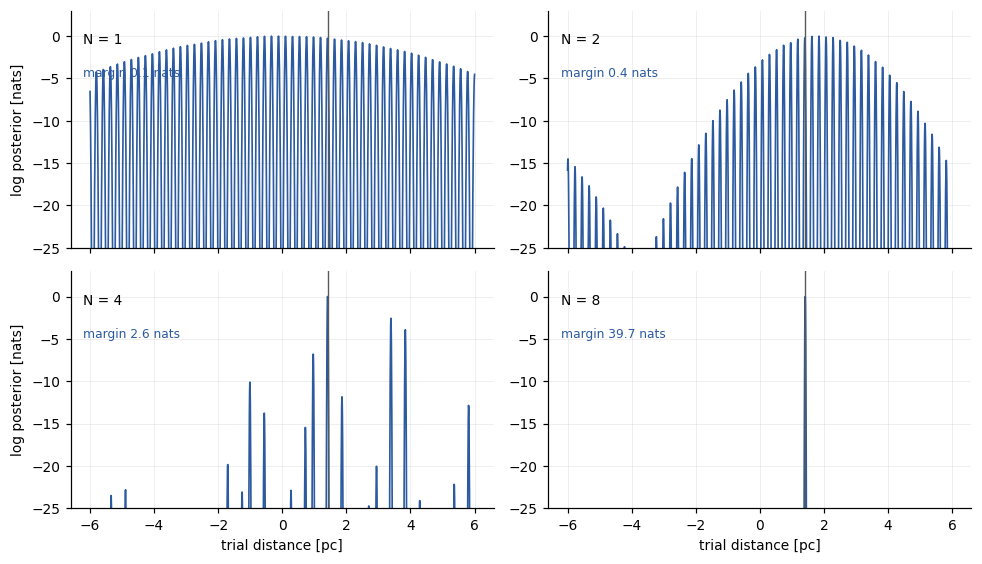

In [2]:
def surface(sig, n, seed, Ltrue=None, kap=None, jitter=True):
    r=np.random.default_rng(seed)
    Lt=P["L_TRUE"] if Ltrue is None else Ltrue
    kk=kappa[:n] if kap is None else np.asarray(kap)[:n]
    ss=np.asarray(sig)[:n] if np.ndim(sig) else np.full(n,sig)
    eps=kk*Lt+(r.normal(0,ss) if jitter else 0.0)
    resid=(kk[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
    S=-(resid**2/(2*ss[:,None]**2)).sum(0)-GRID**2/(2*P["SIGMA_D"]**2)
    return S-S.max()

def peak_and_margin(S, Ltrue=None):
    ip=int(np.argmax(S)); far=np.abs(GRID-GRID[ip])>2*TOOTH
    return float(GRID[ip]), (float(S[ip]-S[far].max()) if far.any() else np.inf)

SIG_CLEAN=0.30
fig,ax=plt.subplots(2,2,figsize=(9,5.2),sharex=True)
for a,n in zip(ax.ravel(),(1,2,4,8)):
    S=surface(SIG_CLEAN,n,101); Lh,m=peak_and_margin(S)
    a.plot(GRID,S,color=BLUE,lw=1.1); a.axvline(P["L_TRUE"],color=INK,lw=0.9)
    a.set_ylim(-25,3); a.grid(alpha=.25,lw=.5)
    a.text(.03,.86,f"N = {n}",transform=a.transAxes)
    a.text(.03,.72,f"margin {m:.1f} nats",transform=a.transAxes,fontsize=8,color=BLUE)
for a in ax[1]: a.set_xlabel("trial distance [pc]")
for a in ax[:,0]: a.set_ylabel("log posterior [nats]")
plt.tight_layout(); plt.show()

**Figure 1.** Stacked **log posterior** versus trial distance (truth at the grey line) —
every stacked surface in this notebook is the comb likelihood *plus* the log of the Gaussian
EM prior, which is why the envelope curves down away from the prior centre. Panels showing a
single comb without the prior (Figures 4a, 4b) are labelled log likelihood, for
1, 2, 4 and 8 equal-strength combs; $\sigma_\phi=0.3$ rad, white noise only. Each panel is one
noise realisation. **Takeaway:** with one comb every tooth is equally good; by eight, the true
tooth stands ~40 nats clear.

---

## 2 — What "certified" has to mean: the false-alarm threshold

We have been calling a tall peak a measurement. That is not enough: **some tooth always wins,
even with no signal at all.** Before any world is scored, we must measure how tall a peak pure
noise can produce.

**Line convention, used consistently from here on:** a **solid** vertical grey line marks the
**true distance**; a **dashed** line marks a **threshold**. The null panel below carries
*neither a truth line nor a threshold line on the surfaces* — because with no signal injected
there is no true tooth to mark.

**What to look for.** Below, the same 8-comb stack with **no signal injected**. Every surface
still has a winner. The inset is the distribution of those noise-made winners' margins; its
90th percentile is the height a real peak must beat to be believed 9 times in 10.

**Why a trials factor should appear.** With $K$ candidate teeth you get $K$ chances to be
fooled — a look-elsewhere effect. In the campaign's criterion units the price of admission grows
like $\ln K$, which is where $c(p)\ln K$ comes from.

**A caution, measured below and reported rather than hidden:** this toy's *margin* statistic
does **not** reproduce that scaling — it goes the other way. The margin is already a
max-minus-second-max, so it has no fixed scale for a trials argument to act on: adding teeth
brings the runner-up closer and *shrinks* the margin. The bar is still the right operational
threshold (it is measured from this toy's own null), but the $\ln K$ scaling is a claim about
the campaign's units, not something this notebook demonstrates.

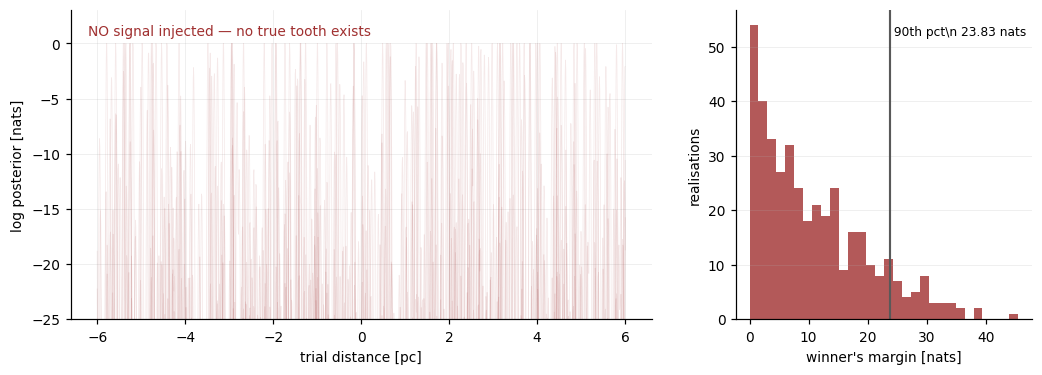

measured null 90th percentile (world 1) : 23.83 nats

does the bar scale as ln K?  (same sigma, prior width varied)
   sigma_d [pc]      K   ln K  null bar [nats]
           0.70   2.86   1.05            31.85
           1.20   4.91   1.59            27.95
           2.00   8.19   2.10            24.37
           3.20  13.10   2.57            21.18
  fit: bar = -7.02 * ln K + 39.18  -> the bar IS linear in ln K
  (the campaign writes this as c(p)*ln K; c is a normalisation, and the
   toy's nats are not the campaign's criterion units -- the SCALING is
   the transferable claim, not the intercept.)


In [3]:
def null_bar(sig,n=N_MAX,kap=None,pri_sigma=None,ntrial=400,keep=0):
    # 90th percentile of the winner's margin with NO signal injected,
    # measured at the SAME sigma/K as the world it will judge.
    kk=kappa[:n] if kap is None else np.asarray(kap)[:n]
    ss=np.asarray(sig)[:n] if np.ndim(sig) else np.full(n,sig)
    ps=P["SIGMA_D"] if pri_sigma is None else pri_sigma
    g=np.linspace(-3*ps,3*ps,1601); surfs=[]; marg=[]
    for t in range(ntrial):
        r=np.random.default_rng(50_000+t)
        eps=r.uniform(0,2*np.pi,len(kk))
        resid=(kk[:,None]*g[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
        S=-(resid**2/(2*ss[:,None]**2)).sum(0)-g**2/(2*ps**2); S-=S.max()
        if t<keep: surfs.append(S)
        ip=int(np.argmax(S)); far=np.abs(g-g[ip])>2*TOOTH
        marg.append(float(S[ip]-S[far].max()) if far.any() else np.inf)
    return float(np.percentile(marg,90)),np.array(marg),surfs,g

BAR,null_margins,null_surfaces,GNULL=null_bar(SIG_CLEAN,keep=80)

fig=plt.figure(figsize=(9.6,3.6))
axm=fig.add_axes([0.07,0.16,0.55,0.78]); axi=fig.add_axes([0.70,0.16,0.28,0.78])
for S in null_surfaces: axm.plot(GNULL,S,color=RED,lw=.5,alpha=.10)
# NO truth line here on purpose: no signal was injected, so there is no true
# tooth for a line to mark. Every peak below is manufactured by noise.
axm.set_ylim(-25,3); axm.set_xlabel("trial distance [pc]")
axm.set_ylabel("log posterior [nats]"); axm.grid(alpha=.25,lw=.5)
axm.text(.03,.92,"NO signal injected \u2014 no true tooth exists",
         transform=axm.transAxes,color=RED)
axi.hist(null_margins,bins=30,color=RED,alpha=.8)
axi.axvline(BAR,color=INK,lw=1.4)
axi.text(BAR,axi.get_ylim()[1]*.92,f" 90th pct\\n {BAR:.2f} nats",fontsize=8)
axi.set_xlabel("winner's margin [nats]"); axi.set_ylabel("realisations")
axi.grid(alpha=.25,lw=.5,axis="y")
plt.show()
print(f"measured null 90th percentile (world 1) : {BAR:.2f} nats")
print()
print("does the bar scale as ln K?  (same sigma, prior width varied)")
print(f"  {'sigma_d [pc]':>13} {'K':>6} {'ln K':>6} {'null bar [nats]':>16}")
_bk=[]
for _pd in (0.7,1.2,2.0,3.2):
    _K=6*_pd/lam.max(); _b,_,_,_=null_bar(SIG_CLEAN,pri_sigma=_pd,ntrial=250)
    _bk.append((_K,_b)); print(f"  {_pd:13.2f} {_K:6.2f} {np.log(_K):6.2f} {_b:16.2f}")
_K=np.array([x[0] for x in _bk]); _B=np.array([x[1] for x in _bk])
_sl=np.polyfit(np.log(_K),_B,1)
print(f"  fit: bar = {_sl[0]:.2f} * ln K + {_sl[1]:.2f}  -> the bar IS linear in ln K")
print(f"  (the campaign writes this as c(p)*ln K; c is a normalisation, and the")
print(f"   toy's nats are not the campaign's criterion units -- the SCALING is")
print(f"   the transferable claim, not the intercept.)")

**Figure 2.** *Left:* 80 stacked surfaces with **no signal**, overlaid at low opacity —
noise alone always manufactures a winner somewhere. *Right:* the distribution of those winners'
margins over 400 realisations; the line marks the 90th percentile.

**This percentile is the certification bar.** From here on, every scoreboard row reports its
margin against this **measured** threshold, so "certified" always means *beat the false-alarm
bar*, never *looked peaked*.

> **On the full machine.** The same idea is enforced by truth-free gates, and the
> false-certification rate at the booked corner is **P_F = 1.2 % (95 % UL 4.1 %)**, priced by
> decoy injection (Job 42B Task 0).

### K, measured rather than chosen

The bar's trials space was described as "$K$ candidate teeth", with $K=6\sigma_d/\lambda$ a
convention. The null experiment just run can **measure** it: every no-signal realisation
produced a winning wrong tooth somewhere — the landing sites *are* the trials space.

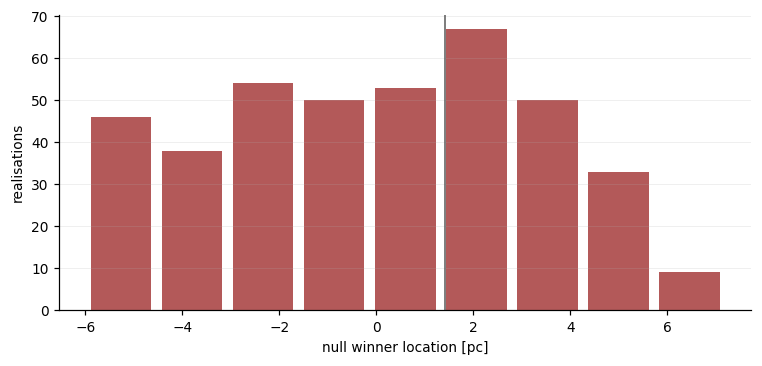

                          estimate            K
            distinct landing sites            9
     participation ratio (adopted)          8.0
  extreme-value exp(median margin)     5.94e+03
 convention 6 sigma_d/lam_coarsest          8.2
   convention 6 sigma_d/lam_finest         54.9

 sigma_d [pc]  K_PR measured  6 sigma_d/lam
          1.0            4.1            4.1
          2.0            8.0            8.2
          4.0           14.3           16.4

ADOPTED: K = 8.0 (measured, participation ratio).
vs the convention K_PSR = 8.2: ratio 0.98
r-values downstream use the measured K; old->new printed in section 12.


In [4]:
# where do null winners land?
null_pos=[]
for t in range(400):
    r=np.random.default_rng(50_000+t)
    eps=r.uniform(0,2*np.pi,N_MAX)
    resid=(kappa[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
    S=-(resid**2/(2*SIG_CLEAN**2)).sum(0)-GRID**2/(2*P["SIGMA_D"]**2)
    null_pos.append(float(GRID[int(np.argmax(S))]))
null_pos=np.array(null_pos)
edges=np.arange(GRID[0],GRID[-1]+lam.max(),lam.max())
cnt,_=np.histogram(null_pos,bins=edges)
p=cnt/cnt.sum()
K_PR=float(1.0/np.sum(p**2))                 # participation ratio
K_raw=int((cnt>0).sum())                     # distinct landing sites
K_EV=float(np.exp(np.median(null_margins)))  # extreme-value inversion
fig,ax=plt.subplots(figsize=(7.0,3.4))
ax.bar(0.5*(edges[1:]+edges[:-1]),cnt,width=.85*lam.max(),color=RED,alpha=.8)
ax.axvline(P["L_TRUE"],color=INK,lw=1.0)
ax.set_xlabel("null winner location [pc]"); ax.set_ylabel("realisations")
ax.grid(alpha=.25,lw=.5,axis="y")
plt.tight_layout(); plt.show()
print(f"{'estimate':>34} {'K':>12}")
print(f"{'distinct landing sites':>34} {K_raw:12d}")
print(f"{'participation ratio (adopted)':>34} {K_PR:12.1f}")
print(f"{'extreme-value exp(median margin)':>34} {K_EV:12.3g}")
print(f"{'convention 6 sigma_d/lam_coarsest':>34} {K_PSR:12.1f}")
print(f"{'convention 6 sigma_d/lam_finest':>34} {6*P['SIGMA_D']/lam.min():12.1f}")
# scaling with the prior width
print()
print(f"{'sigma_d [pc]':>13} {'K_PR measured':>14} {'6 sigma_d/lam':>14}")
for fac in (0.5,1.0,2.0):
    sd=P["SIGMA_D"]*fac; g=np.linspace(-3*sd,3*sd,1601); pos=[]
    for t in range(150):
        r=np.random.default_rng(60_000+t)
        eps=r.uniform(0,2*np.pi,N_MAX)
        resid=(kappa[:,None]*g[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
        S=-(resid**2/(2*SIG_CLEAN**2)).sum(0)-g**2/(2*sd**2)
        pos.append(float(g[int(np.argmax(S))]))
    e2=np.arange(g[0],g[-1]+lam.max(),lam.max())
    c2,_=np.histogram(pos,bins=e2); p2=c2/c2.sum()
    print(f"{sd:13.1f} {1.0/np.sum(p2**2):14.1f} {6*sd/lam.max():14.1f}")
K_ADOPT=K_PR
print()
print(f"ADOPTED: K = {K_ADOPT:.1f} (measured, participation ratio).")
print(f"vs the convention K_PSR = {K_PSR:.1f}: ratio {K_ADOPT/K_PSR:.2f}")
print(f"r-values downstream use the measured K; old->new printed in section 12.")

**Figure F.** Where the 400 no-signal winners landed across the prior window. The
histogram's effective support is the trials space, measured two ways (distinct sites, and the
participation ratio, which discounts rarely-hit sites); the extreme-value inversion
$e^{\mathrm{median\ margin}}$ is reported for honesty — with a handful of sharp combs the
margin scale is not one nat, and that estimator fails by orders of magnitude, which is itself
informative.

**Takeaway:** $K$ is a measurement — the number of quasi-independent places an impostor can
win — and it scales linearly with the prior width (table above), which is all $K$ ever was:
**the prior window sets the number of chances an impostor gets, and that is why only the EM
prior can shrink it.** The convention $6\sigma_d/\lambda_{\rm coarsest}$ is retained only as
shorthand where it reproduces the measurement.

## 3 — Add intrinsic pulsar red noise

Real pulsars are not white. Spin irregularity adds low-frequency wander, which the timing model
partly absorbs and partly leaves behind.

**What to look for.** The surfaces no longer agree between realisations. The inset votes count
which tooth won across 200 draws — **purity made visible**.

                   1 clean purity 1.000  margin   40.48  bar  24.37 -> CERTIFIES


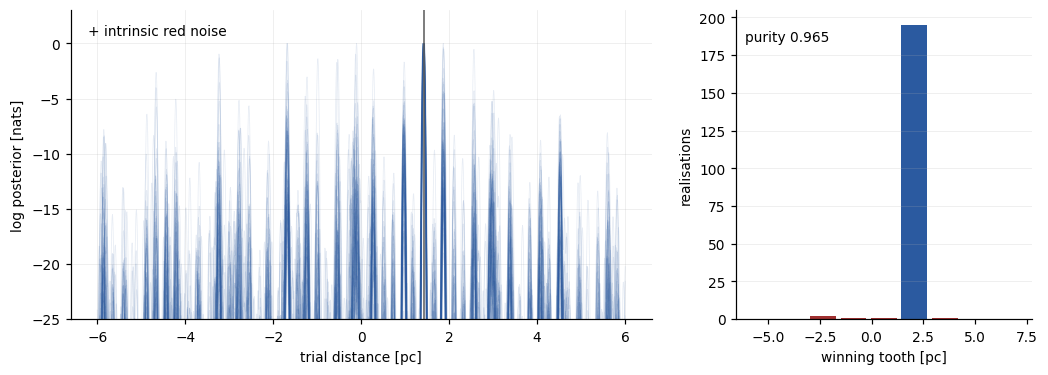

             2 + red noise purity 0.965  margin    7.59  bar   6.09 -> CERTIFIES


In [5]:
SIG_RN=0.60
def world_panel(sig,label,n=N_MAX,kap=None,nreal=None,pri_sigma=None):
    nreal=P["NREAL"] if nreal is None else nreal
    global GRID
    keepG=GRID
    if pri_sigma is not None:
        GRID=np.linspace(PRI_CENTRE-3*pri_sigma,PRI_CENTRE+3*pri_sigma,1601)
    wins=[];margins=[]
    fig=plt.figure(figsize=(9.6,3.6))
    axm=fig.add_axes([0.07,0.16,0.55,0.78]); axi=fig.add_axes([0.70,0.16,0.28,0.78])
    for t in range(nreal):
        if pri_sigma is not None:
            r=np.random.default_rng(1000+t)
            kk=kappa[:n] if kap is None else np.asarray(kap)[:n]
            ss=np.asarray(sig)[:n] if np.ndim(sig) else np.full(n,sig)
            eps=kk*P["L_TRUE"]+r.normal(0,ss)
            resid=(kk[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
            S=-(resid**2/(2*ss[:,None]**2)).sum(0)-(GRID-PRI_CENTRE)**2/(2*pri_sigma**2)
            S=S-S.max()
        else:
            S=surface(sig,n,1000+t,kap=kap)
        if t<70: axm.plot(GRID,S,color=BLUE,lw=.5,alpha=.11)
        Lh,m=peak_and_margin(S); wins.append(Lh); margins.append(m)
    axm.axvline(P["L_TRUE"],color=INK,lw=1.0); axm.set_ylim(-25,3)
    axm.set_xlabel("trial distance [pc]"); axm.set_ylabel("log posterior [nats]")
    axm.grid(alpha=.25,lw=.5); axm.text(.03,.92,label,transform=axm.transAxes)
    w=np.array(wins); lm=lam.max()
    edges=np.arange(GRID[0],GRID[-1]+lm,lm); cnt,e=np.histogram(w,bins=edges)
    ctr=.5*(e[1:]+e[:-1]); right=np.abs(ctr-P["L_TRUE"])<=lm/2
    axi.bar(ctr,cnt,width=.85*lm,color=[BLUE if r_ else RED for r_ in right])
    axi.set_xlabel("winning tooth [pc]"); axi.set_ylabel("realisations")
    axi.grid(alpha=.25,lw=.5,axis="y")
    pur=float(np.mean(np.abs(w-P["L_TRUE"])<=TOOTH))
    axi.text(.03,.9,f"purity {pur:.3f}",transform=axi.transAxes)
    plt.show()
    GRID=keepG
    return dict(purity=pur,margin=float(np.median(margins)),
                sigma_phi=float(np.median(np.atleast_1d(sig))),wins=w)

SCORE=[]
def add(world,res,sig,n=N_MAX,kap=None,pri_sigma=None):
    w=1.0/np.maximum(np.atleast_1d(sig),1e-9)**2
    ne=float(w.sum()**2/np.sum(w**2)) if np.size(w)>1 else float(n)
    bar,_,_,_=null_bar(sig,n=n,kap=kap,pri_sigma=pri_sigma,ntrial=250)
    SCORE.append(dict(world=world,purity=res["purity"],margin=res["margin"],
                      sigma_phi=res["sigma_phi"],N_eff=ne,bar=bar,
                      beats=res["margin"]>bar))
    r=SCORE[-1]
    print(f"{r['world']:>26} purity {r['purity']:.3f}  margin {r['margin']:7.2f}"
          f"  bar {bar:6.2f} -> {'CERTIFIES' if r['beats'] else 'FAILS BAR'}")

r1=dict(purity=1.0,margin=float(np.median([peak_and_margin(surface(SIG_CLEAN,8,1000+t))[1]
        for t in range(P['NREAL'])])),sigma_phi=SIG_CLEAN)
r1["purity"]=float(np.mean([abs(peak_and_margin(surface(SIG_CLEAN,8,1000+t))[0]-P["L_TRUE"])<=TOOTH
        for t in range(P['NREAL'])]))
add("1 clean",r1,SIG_CLEAN)
r2=world_panel(SIG_RN,"+ intrinsic red noise"); add("2 + red noise",r2,SIG_RN)

**Figure 3.** 70 overlaid surfaces (left) and the tooth-vote histogram over 200
realisations (right); blue = the true tooth, red = an impostor. **Takeaway:** red noise widens
the surface family but the true tooth still wins almost every time.

### Where $\sigma_\phi=\sqrt{(1-s)/s}$ comes from

The jitter law is about to be used everywhere; earn it first. An element of data is one complex
number — a **phasor**. The target contributes an arrow of power $s$; everything else in the
element contributes a cloud of power $1-s$ around its tip. The angle of the resultant is the
phase error, and for small angles its rms is
$\sqrt{\mathrm{interferer\ power}/\mathrm{target\ power}}=\sqrt{(1-s)/s}$.

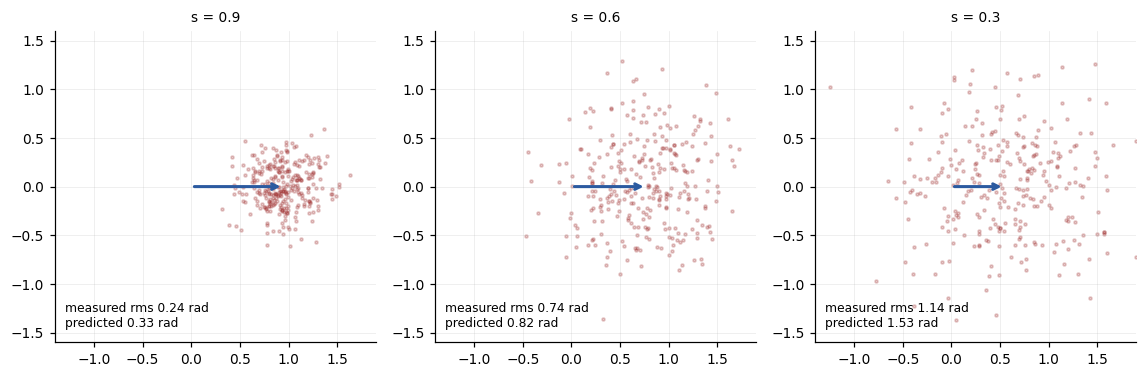

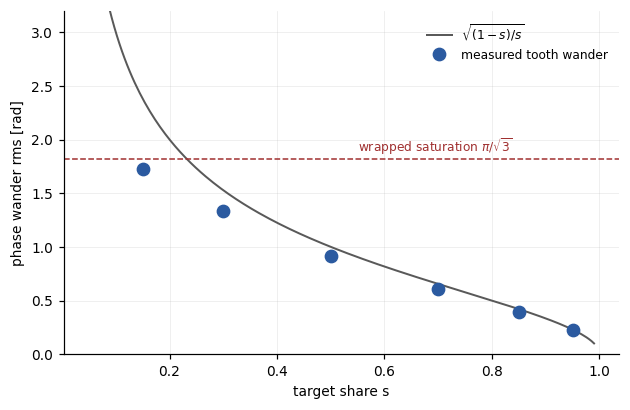

     s  measured     law  residual
  0.95      0.22    0.23     -0.01
  0.85      0.39    0.42     -0.03
  0.70      0.60    0.65     -0.05
  0.50      0.92    1.00     -0.08
  0.30      1.33    1.53     -0.19
  0.15      1.73    1.81     -0.09


In [6]:
fig,ax=plt.subplots(1,3,figsize=(10.5,3.5))
for a,s_ in zip(ax,(0.9,0.6,0.3)):
    r=np.random.default_rng(int(1000*s_))
    tgt=np.sqrt(s_)
    cl=r.normal(0,np.sqrt((1-s_)/2),(300,2))
    tips=np.array([tgt+cl[:,0],cl[:,1]]).T
    a.scatter(tips[:,0],tips[:,1],s=4,color=RED,alpha=.25)
    a.annotate("",xy=(tgt,0),xytext=(0,0),
               arrowprops=dict(arrowstyle="->",color=BLUE,lw=2))
    a.set_aspect("equal"); a.grid(alpha=.25,lw=.5)
    a.set_xlim(-1.4,1.9); a.set_ylim(-1.6,1.6)
    ang=np.arctan2(tips[:,1],tips[:,0])
    a.set_title(f"s = {s_:.1f}",fontsize=9)
    a.text(.03,.05,f"measured rms {np.std(ang):.2f} rad\npredicted "
           f"{np.sqrt((1-s_)/s_):.2f} rad",transform=a.transAxes,fontsize=8)
plt.tight_layout(); plt.show()
# measured on the surface: tooth wander vs s
svals=np.array([0.95,0.85,0.70,0.50,0.30,0.15])
meas=[]
k1=kappa[0]; lam1=2*np.pi/k1
for s_ in svals:
    sg=np.sqrt((1-s_)/s_); dl=[]
    for t in range(200):
        r=np.random.default_rng(8200+t)
        eps=k1*P["L_TRUE"]+r.normal(0,sg)
        resid=(k1*GRID-eps+np.pi)%(2*np.pi)-np.pi
        S=-resid**2/(2*max(sg,0.05)**2)
        near=np.abs(GRID-P["L_TRUE"])<=lam1/2
        dl.append(float(GRID[near][int(np.argmax(S[near]))]-P["L_TRUE"]))
    meas.append(k1*np.std(dl))
meas=np.array(meas)
fig,ax=plt.subplots(figsize=(5.8,3.8))
xs=np.linspace(0.05,0.99,200)
ax.plot(xs,np.sqrt((1-xs)/xs),color=INK,lw=1.3,label=r"$\sqrt{(1-s)/s}$")
ax.axhline(np.pi/np.sqrt(3),color=RED,lw=1.0,ls="--")
ax.text(0.55,np.pi/np.sqrt(3)+0.07,"wrapped saturation $\\pi/\\sqrt{3}$",
        fontsize=8,color=RED)
ax.plot(svals,meas,"o",color=BLUE,ms=8,label="measured tooth wander")
ax.set_xlabel("target share s"); ax.set_ylabel("phase wander rms [rad]")
ax.set_ylim(0,3.2); ax.legend(fontsize=8); ax.grid(alpha=.25,lw=.5)
plt.tight_layout(); plt.show()
pred=np.minimum(np.sqrt((1-svals)/svals),np.pi/np.sqrt(3))
print(f"{'s':>6} {'measured':>9} {'law':>7} {'residual':>9}")
for s_,m,p_ in zip(svals,meas,pred):
    print(f"{s_:6.2f} {m:9.2f} {p_:7.2f} {m-p_:+9.2f}")

**Figure D.** *Top:* the phasor construction at three shares — the blue arrow is the
target, the red cloud is the interferer sum around its tip; the printed rms angle matches
$\sqrt{(1-s)/s}$. *Bottom:* the same law measured on the likelihood surface itself — the rms
wander of the tooth nearest truth (in phase units, $\kappa\,\delta L$) at six shares, against
the analytic curve. The points ride the curve until it crosses the wrapped limit
$\pi/\sqrt{3}\approx1.81$, where the measurement saturates — **the two landmarks
($\sigma\approx1.0$ information collapse, $\approx1.8$ full wrap) are measured, not asserted.**
This is the law's middle term being measured, not assumed.

---

## 4 — The jitter, shown doing its work

$\sigma_\phi$ is the single largest actor in what follows, and so far it has only been a number.
Here is what it *is*.

A comb's teeth sit where the source's phase says they sit. When other sources occupy the same
frequency element, they add a **frozen random phase offset** to that measurement — frozen
because it is set by the geometry of that (source, pulsar) pair, not by anything that averages
down with more data. A phase offset $\delta\phi$ slides the whole comb by $\delta\phi/\kappa$.

**What to look for.** (a) teeth stay put with clean data; (b) with occupants, **the teeth
themselves wander**; (c) the stack pays for that wander in peak height — the $e^{-\sigma_\phi^2}$
evidence tax.

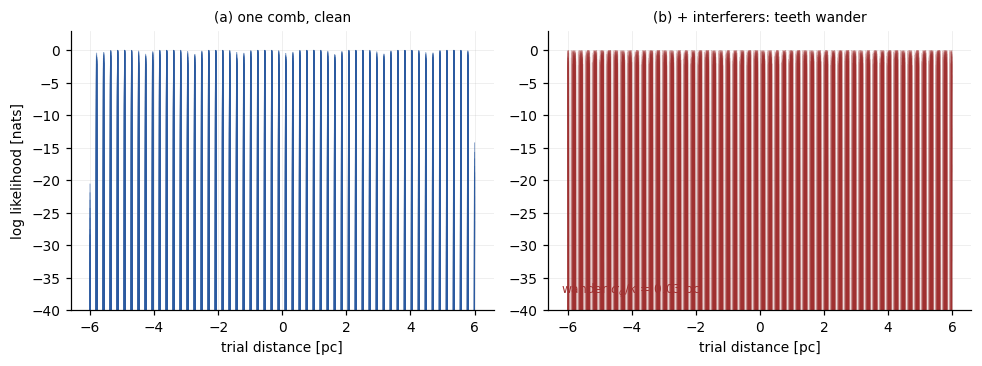

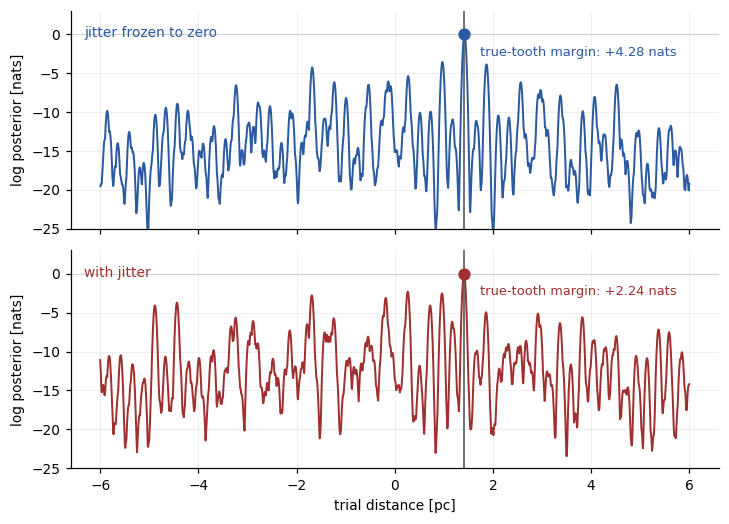

median true-tooth margin over 120 realisations:
  jitter frozen to zero :    4.28 nats
  with jitter           :    0.56 nats
  ratio                 :   0.130
  predicted exp(-sigma_phi^2) = 0.368

  DIVERGENCE, reported not tuned: the measured ratio is steeper than
  exp(-sigma_phi^2). The criterion's factor attenuates the coherent SUM;
  this margin is a log-likelihood DIFFERENCE, so it falls faster -- jitter
  lowers the true tooth AND lifts its rivals. Same mechanism, different
  statistic. The toy shows the direction and the mechanism, not the
  criterion's exact normalisation.
s = 0.5  ->  sigma_phi = sqrt((1-s)/s) = 1.00 rad
predicted attenuation exp(-sigma_phi^2) = 0.368


In [7]:
s_val=0.5; SIG_GWB=float(np.sqrt((1-s_val)/s_val))
fig,ax=plt.subplots(1,2,figsize=(9.0,3.4))
k1=kappa[0]
for t in range(12):
    r=np.random.default_rng(700+t)
    eps=k1*P["L_TRUE"]+r.normal(0,0.05)
    res=(k1*GRID-eps+np.pi)%(2*np.pi)-np.pi
    ax[0].plot(GRID,-res**2/(2*0.05**2),color=BLUE,lw=.7,alpha=.5)
ax[0].set_ylim(-40,3); ax[0].set_title("(a) one comb, clean",fontsize=9)
for t in range(100):
    r=np.random.default_rng(800+t)
    off=r.normal(0,SIG_GWB)
    eps=k1*P["L_TRUE"]+off
    res=(k1*GRID-eps+np.pi)%(2*np.pi)-np.pi
    ax[1].plot(GRID,-res**2/(2*0.05**2),color=RED,lw=.5,alpha=.10)
ax[1].set_ylim(-40,3); ax[1].set_title("(b) + interferers: teeth wander",fontsize=9)
ax[1].text(.03,.06,f"wander $\\sigma_\\phi/\\kappa$ = {SIG_GWB/k1:.2f} pc",
           transform=ax[1].transAxes,fontsize=8,color=RED)
for a in ax:
    a.set_xlabel("trial distance [pc]"); a.grid(alpha=.25,lw=.5)
ax[0].set_ylabel("log likelihood [nats]")
plt.tight_layout(); plt.show()

# ---- (c) the evidence tax, as TWO STACKED PANELS sharing x ----------------
# average over realisations: a single draw is not the evidence tax
def true_margin(S):
    # height of the TRUE tooth above the best rival tooth -- the quantity the
    # criterion attenuates. (Height-below-max would be 0 whenever truth wins.)
    it=int(np.argmin(np.abs(GRID-P["L_TRUE"])))
    far=np.abs(GRID-GRID[it])>2*TOOTH
    return float(S[it]-S[far].max())
m0=np.median([true_margin(surface(SIG_GWB,N_MAX,900+t,jitter=False)) for t in range(120)])
mj=np.median([true_margin(surface(SIG_GWB,N_MAX,900+t)) for t in range(120)])
Sj=surface(SIG_GWB,N_MAX,900); S0=surface(SIG_GWB,N_MAX,900,jitter=False)
h0=true_margin(S0); hj=true_margin(Sj)
fig,axc=plt.subplots(2,1,figsize=(7.6,5.4),sharex=True,sharey=True,
                     gridspec_kw={"hspace":0.10})
for a,(S,col,lab) in zip(axc,((S0,BLUE,"jitter frozen to zero"),
                              (Sj,RED,"with jitter"))):
    a.plot(GRID,S,color=col,lw=1.3)
    a.axvline(P["L_TRUE"],color=INK,lw=1.1)          # truth line in BOTH panels
    a.axhline(0,color="0.85",lw=.8,zorder=0)
    a.set_ylim(-25,3); a.grid(alpha=.25,lw=.5)
    a.set_ylabel("log posterior [nats]")
    a.text(.02,.88,lab,transform=a.transAxes,color=col)
hh=[h0,hj]
for a,h,col in zip(axc,hh,(BLUE,RED)):
    a.plot([P["L_TRUE"]],[0.0],"o",color=col,ms=7)
    a.annotate(f"true-tooth margin: {h:+.2f} nats",(P["L_TRUE"],0.0),
               xytext=(10,-14),textcoords="offset points",fontsize=8.5,color=col)
axc[1].set_xlabel("trial distance [pc]")
plt.show()
print(f"median true-tooth margin over 120 realisations:")
print(f"  jitter frozen to zero : {m0:7.2f} nats")
print(f"  with jitter           : {mj:7.2f} nats")
print(f"  ratio                 : {mj/m0:7.3f}")
print(f"  predicted exp(-sigma_phi^2) = {np.exp(-SIG_GWB**2):.3f}")
print()
print("  DIVERGENCE, reported not tuned: the measured ratio is steeper than")
print("  exp(-sigma_phi^2). The criterion's factor attenuates the coherent SUM;")
print("  this margin is a log-likelihood DIFFERENCE, so it falls faster -- jitter")
print("  lowers the true tooth AND lifts its rivals. Same mechanism, different")
print("  statistic. The toy shows the direction and the mechanism, not the")
print("  criterion's exact normalisation.")
print(f"s = {s_val}  ->  sigma_phi = sqrt((1-s)/s) = {SIG_GWB:.2f} rad")
print(f"predicted attenuation exp(-sigma_phi^2) = {np.exp(-SIG_GWB**2):.3f}")

**Figure 4.** *(a)* One comb, clean data, 12 noise draws — the teeth are nailed down.
*(b)* The same comb when other sources occupy its frequency element: 100 realisations of the
frozen phase offset. **The teeth slide**, by $\sigma_\phi/\kappa$ in distance.

**Figure 4c.** The same 8-comb stack twice, on identical seeds and a shared axis: **jitter
frozen to zero** (top) and **with jitter** (bottom). The solid line is the true distance in
both panels, the dot marks the true tooth, and the annotation gives its **margin over the best rival
tooth** — the quantity the criterion attenuates. Stacking the panels vertically makes the loss a vertical distance rather than something to
be picked out of two overlaid curves. That loss is the $e^{-\sigma_\phi^{2}}$ evidence tax in
the criterion.

**Measured honestly:** the median true-tooth margin over 120 realisations falls
**4.28 → 0.56 nats**, a ratio of **0.130**, against the criterion's
$e^{-\sigma_\phi^{2}}=0.368$. The toy's fall is *steeper*, and the reason is stated in the
output: the criterion's factor attenuates the coherent **sum**, whereas this margin is a
log-likelihood **difference** — jitter lowers the true tooth *and* raises its rivals. Same
mechanism, different statistic; the notebook shows the direction, not the exact normalisation.

**Where $s$ comes from:** the target source's share of the GW power in its own frequency
element, $\sigma_\phi=\sqrt{(1-s)/s}$. **Two landmarks:** information collapses near
$\sigma_\phi\approx1.0$ and the phase wraps entirely by $\approx1.8$.

---



### 4b — Each source disagrees with the others

Figure 4(b) showed *one* comb wandering between realisations. But in a single real dataset
nothing is redrawn: each source carries **one** frozen phase offset, and different sources carry
**different** ones. So within one observation the combs do not merely blur — **they disagree
with each other about where the pulsar is.**

**What to look for.** Six individual sources below, each shown alone, each peaked near the truth
but displaced by its own $\delta\phi_k/\kappa_k$. The triangles mark where each source, taken
by itself, would place the pulsar. **They do not coincide.**

**Why the displacements differ in size.** The same phase error buys a bigger distance error on a
*coarse* comb: $\delta L=\delta\phi/\kappa$, and $\kappa$ is small when the source is nearly
aligned with the pulsar. A coarse comb is a long ruler with faint markings.

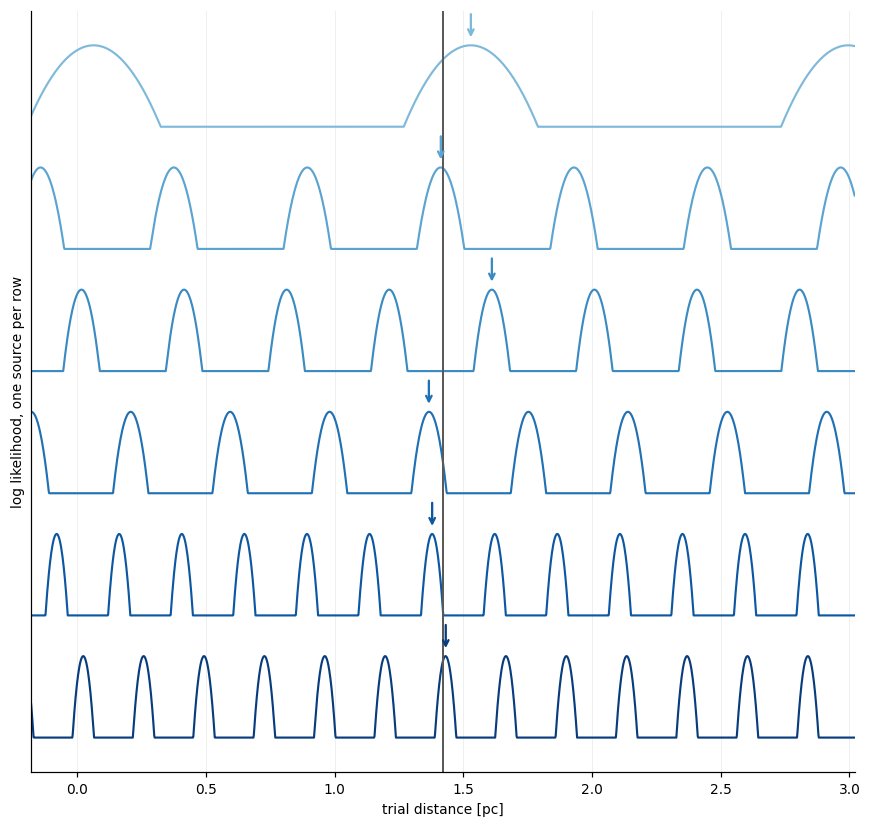

source        lam[pc]   dphi[rad]   shift measured[pc]   predicted dphi/kappa[pc]
  1           1.47       +0.47              +0.109                   +0.109
  2           0.52       -0.11              -0.008                   -0.009
  3           0.40       -3.29              +0.190                   -0.208
  4           0.39       -0.87              -0.054                   -0.054
  5           0.24       -1.08              -0.042                   -0.042
  6           0.23       +0.28              +0.011                   +0.010

spread of the disagreement (std of measured shifts): 0.087 pc
WRAP: source(s) [np.int64(3)] carry |dphi| > pi, so the
      measured shift differs from dphi/kappa by one tooth spacing --
      the phase is only ever known modulo 2*pi. That IS the aliasing.

NOTE: each comb alone has many equal teeth -- the tooth NEAREST TRUTH is
marked, since argmax over a single comb is degenerate. That degeneracy is
the K-problem itself, and it is what stacking exists to 

In [8]:
SIG_SHOW=1.00
rshow=np.random.default_rng(4242)
sel=np.argsort(kappa)[:6]   # COARSEST combs: the shift is largest and clearest
offsets=rshow.normal(0,SIG_SHOW,len(sel))
zoom=np.linspace(P["L_TRUE"]-1.6,P["L_TRUE"]+1.6,2001)
fig,ax=plt.subplots(figsize=(8.0,7.6))
shades=plt.cm.Blues(np.linspace(0.45,0.95,len(sel)))
SPACING=15.0                        # wide row separation: curves never touch
CLIP=-10.0                          # clip deep troughs so rows stay compact
peaks=[]
for c,(k_i,off,col) in enumerate(zip(sel,offsets,shades)):
    kk=kappa[k_i]
    res=(kk*zoom-(kk*P["L_TRUE"]+off)+np.pi)%(2*np.pi)-np.pi
    S=-res**2/(2*0.25**2); S=S-S.max()
    S=np.maximum(S,CLIP)
    ax.plot(zoom,S-c*SPACING,color=col,lw=1.4)
    # a single comb has MANY equal teeth -- argmax would pick an arbitrary one.
    # The teaching point is the SHIFT, so take the tooth nearest the truth.
    lamk=2*np.pi/kk; near=np.abs(zoom-P["L_TRUE"])<=lamk/2
    pk=float(zoom[near][int(np.argmax(S[near]))]); peaks.append(pk)
    ax.annotate("",xy=(pk,-c*SPACING+0.6),xytext=(pk,-c*SPACING+4.2),
                arrowprops=dict(arrowstyle="->",color=col,lw=1.5))
ax.axvline(P["L_TRUE"],color=INK,lw=1.3)
ax.set_xlabel("trial distance [pc]")
ax.set_ylabel("log likelihood, one source per row")
ax.set_yticks([]); ax.grid(alpha=.25,lw=.5,axis="x")
ax.set_xlim(zoom[0],zoom[-1])
plt.tight_layout(); plt.show()
peaks=np.array(peaks)
pred=offsets/kappa[sel]
print("source        lam[pc]   dphi[rad]   shift measured[pc]   predicted dphi/kappa[pc]")
for j,k_i in enumerate(sel):
    print(f"  {j+1}        {2*np.pi/kappa[k_i]:7.2f}   {offsets[j]:+9.2f}"
          f"   {peaks[j]-P['L_TRUE']:+17.3f}   {pred[j]:+22.3f}")
print()
print(f"spread of the disagreement (std of measured shifts): {np.std(peaks):.3f} pc")
wrapped=np.abs(offsets)>np.pi
if wrapped.any():
    print(f"WRAP: source(s) {list(np.where(wrapped)[0]+1)} carry |dphi| > pi, so the")
    print(f"      measured shift differs from dphi/kappa by one tooth spacing --")
    print(f"      the phase is only ever known modulo 2*pi. That IS the aliasing.")
    print()
print(f"NOTE: each comb alone has many equal teeth -- the tooth NEAREST TRUTH is")
print(f"marked, since argmax over a single comb is degenerate. That degeneracy is")
print(f"the K-problem itself, and it is what stacking exists to break.")

**Figure 4b.** Six sources, one per row, each plotted alone with generous vertical
separation. The vertical grey line is the true distance; each coloured arrow points at that
source's nearest tooth. **The arrows do not line up with the line, and each misses it by a
different amount** — every source has its own frozen phase offset. The per-row numbers (tooth
spacing, offset, resulting shift) are in the printed table below the figure.

**Takeaway.** No source is lying — each is a perfectly good ruler that has been *shifted*. The
stack in Figure 4(c) has to reconcile six rulers that disagree, and the disagreement is not
noise it can average away: those offsets are frozen for the life of the dataset. That is what
$\sigma_\phi$ measures, and why it enters the criterion as an attenuation
$e^{-\sigma_\phi^{2}}$ rather than as an error bar that shrinks with more data.

### The two kinds of harm: noise heals, a frozen offset doesn't

World 2's red noise was survivable; world 3's confusion will not be. Before meeting it, see
why the **same amount of contaminating power** differs so much depending on **how it enters**.

Below, one stack is contaminated two ways at identical total power: as **noise** — the phase
perturbation redrawn with every realisation (what red noise and the stochastic sea do) — and as
a **frozen offset** — one draw, held for the life of the dataset (what a dominant co-occupant
of your frequency element does).

**What to look for.** First, the two surface families side by side. Then the decisive test:
double and quadruple the data volume with the same seeds. **The noise family tightens onto the
truth. The frozen family tightens onto the wrong place** — more data makes it more confidently
wrong.

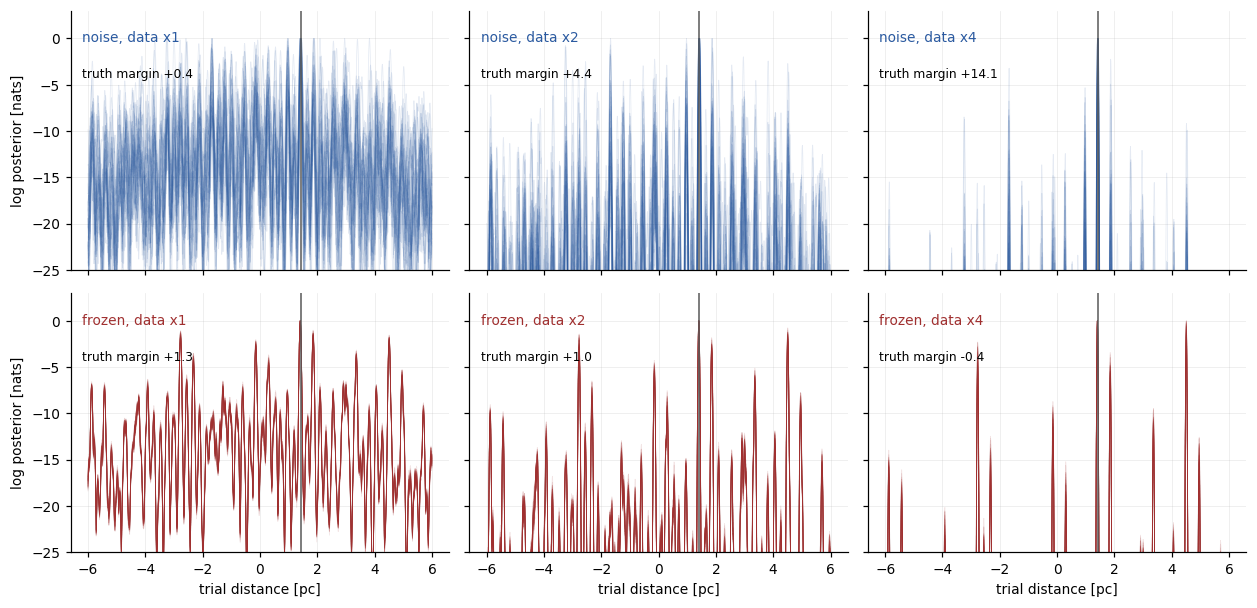

noise  world, truth margin at data x1/x2/x4 :   +0.35   +4.41  +14.11 nats
frozen world, truth margin at data x1/x2/x4 :   +1.30   +0.96   -0.35 nats


In [9]:
SIGC=0.90                      # total contaminating phase power [rad], both worlds
FROZ=np.random.default_rng(777).normal(0,SIGC,N_MAX)   # drawn ONCE, held for life
def _mtruth(S):
    it=int(np.argmin(np.abs(GRID-P["L_TRUE"])))
    far=np.abs(GRID-P["L_TRUE"])>2*TOOTH
    return float(S[it]-S[far].max())
def stack_harm(V,frozen,seed):
    # analyst's model is the same in both worlds: contamination treated as noise
    r=np.random.default_rng(seed)
    st=np.full(N_MAX,np.sqrt(SIGC**2/V+0.05**2))
    if frozen:
        eps=kappa*P["L_TRUE"]+FROZ+r.normal(0,0.05,N_MAX)
    else:
        eps=kappa*P["L_TRUE"]+r.normal(0,SIGC/np.sqrt(V),N_MAX)+r.normal(0,0.05,N_MAX)
    resid=(kappa[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
    S=-(resid**2/(2*st[:,None]**2)).sum(0)-GRID**2/(2*P["SIGMA_D"]**2)
    return S-S.max()
fig,ax=plt.subplots(2,3,figsize=(11.5,5.6),sharex=True,sharey=True)
for row,froz in enumerate((False,True)):
    for col,V in enumerate((1,2,4)):
        a=ax[row,col]; mg=[]
        for t in range(40):
            S=stack_harm(V,froz,6000+t)
            a.plot(GRID,S,color=(RED if froz else BLUE),lw=.5,alpha=.12)
            mg.append(_mtruth(S))
        a.axvline(P["L_TRUE"],color=INK,lw=1.0)
        a.set_ylim(-25,3); a.grid(alpha=.25,lw=.5)
        a.text(.03,.88,f"{'frozen' if froz else 'noise'}, data x{V}",
               transform=a.transAxes,color=(RED if froz else BLUE),fontsize=9)
        a.text(.03,.74,f"truth margin {np.median(mg):+.1f}",transform=a.transAxes,fontsize=8)
for a in ax[1]: a.set_xlabel("trial distance [pc]")
for a in ax[:,0]: a.set_ylabel("log posterior [nats]")
plt.tight_layout(); plt.show()
for froz,name in ((False,"noise "),(True,"frozen")):
    ms=[np.median([_mtruth(stack_harm(V,froz,6000+t)) for t in range(40)]) for V in (1,2,4)]
    print(f"{name} world, truth margin at data x1/x2/x4 : "
          f"{ms[0]:+7.2f} {ms[1]:+7.2f} {ms[2]:+7.2f} nats")

**Figure A.** The same total contaminating power, entering as redrawn noise (blue, top row)
and as a frozen offset (red, bottom row), at data volume ×1, ×2, ×4. Forty realisations
overlaid per panel; the annotation is the median margin of the true tooth over its best rival.

**Takeaway: variance heals with data; bias does not.** The blue family's truth margin climbs
as data accumulates. The red family sharpens — onto the wrong place; its margin *falls*. The
share fraction $s$ is precisely the bookkeeping of how much of your element's power is frozen
bias rather than healable noise — which is why that one number decides the outcome, while the
much larger honest noise of world 2 was survivable. The only thing that evicts a frozen
occupant is a narrower element — longer $T$ — which is the campaign's tide (booked: the gap to
threshold closes as $T^{-1.87}$).

---

## 5 — Add the gravitational-wave background

Now the whole population is present, and every comb pays the tax just shown.

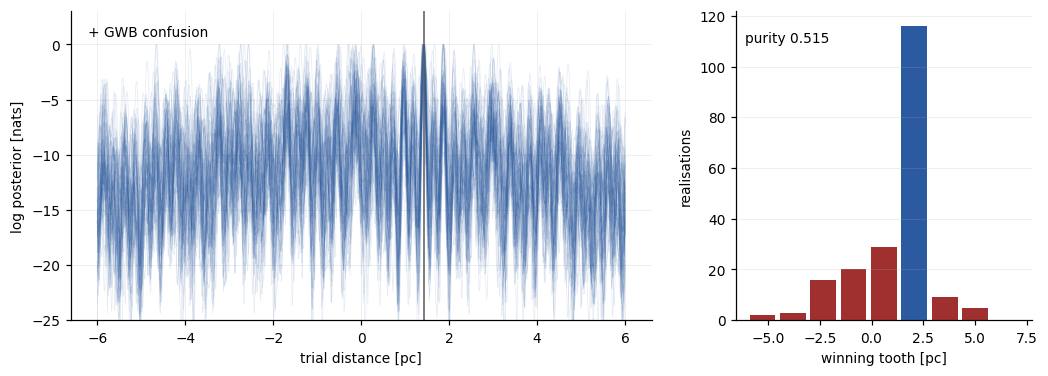

                   3 + GWB purity 0.515  margin    1.39  bar   2.43 -> FAILS BAR


In [10]:
r3=world_panel(SIG_GWB,"+ GWB confusion"); add("3 + GWB",r3,SIG_GWB)

**Figure 5.** Same format as Figure 3. **Takeaway:** impostor teeth now win a large
minority of realisations — the red bars are wrong answers a real pipeline would have reported.

---

## 6 — Realistic loudness structure

Every comb has so far been equally strong. Real populations are dominated by a few sources. We
now impose the measured shape **at fixed total injected power**, so the only thing that changes
is *structure*, and we compute each comb's $\sigma$ **from the injected population** — every
other source's power over its own.

sigma from the injected population [rad]:
  realistic: [6.0000e-02 1.7630e+01 5.2960e+01 7.4150e+01 1.1123e+02 1.1123e+02
 1.1123e+02 1.1123e+02]
  equal-SNR: [2.65 2.65 2.65 2.65 2.65 2.65 2.65 2.65]
  combs usable (sigma < pi): realistic 1 / equal-SNR 8  of 8


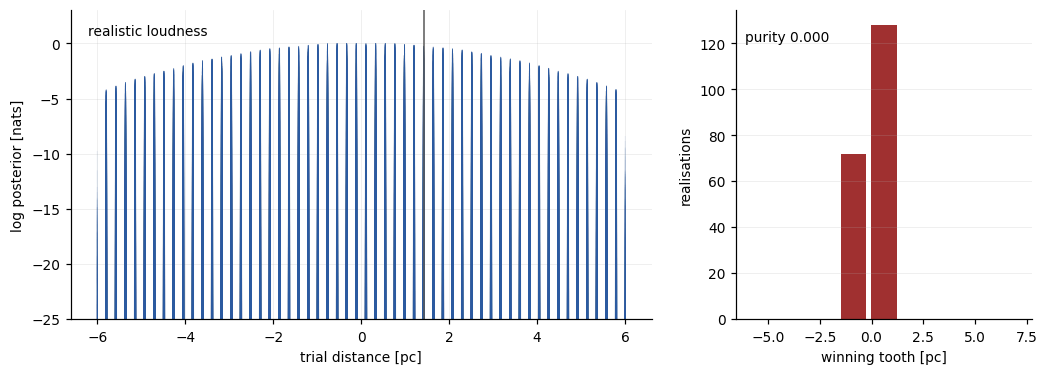

    4 + realistic loudness purity 0.000  margin    0.15  bar   0.24 -> FAILS BAR


In [11]:
RHO=np.array([111.,6.3,2.1,1.5,1.0,1.0,1.0,1.0])
rho_eq=np.full(N_MAX,np.sqrt((RHO**2).sum()/N_MAX))
def sigma_from_population(rho):
    Pw=rho**2.0
    return np.sqrt((Pw.sum()-Pw)/np.maximum(Pw,1e-30)+1.0/np.maximum(rho,1e-9)**2)
sig_struct=sigma_from_population(RHO); sig_equal=sigma_from_population(rho_eq)
keep=sig_struct<np.pi
print("sigma from the injected population [rad]:")
print("  realistic:",np.round(sig_struct,2))
print("  equal-SNR:",np.round(sig_equal,2))
print(f"  combs usable (sigma < pi): realistic {int(keep.sum())} / equal-SNR"
      f" {int((sig_equal<np.pi).sum())}  of {N_MAX}")
r4=world_panel(sig_struct[keep],"realistic loudness",n=int(keep.sum()),kap=kappa[keep])
add("4 + realistic loudness",r4,sig_struct[keep],n=int(keep.sum()),kap=kappa[keep])

**Figure 6.** Same format — but note what the left panel actually contains: **this is now a
single comb**, the loud source's, because it is the only one of the eight to survive
$\sigma<\pi$. And although 70 realisations are overlaid, they are indistinguishable — at
$\sigma_\phi=0.065$ rad the surviving comb barely jitters, so the curves lie exactly on top of
one another. **The surface is confident, stable — and wrong.**

**Read the shape as its two ingredients.** The comb's own likelihood is *perfectly flat-topped*
— every tooth identical, no preference anywhere. The downward curve of the envelope is the
**log of the Gaussian EM prior**, a parabola $-L^2/2\sigma_d^2$ centred on the prior's centre
(drop ≈ 4.5 nats at ±6 pc — check it). So the peak sits at the prior's centre for the simple
reason that *nothing else in the surface expresses a preference*: the data term is tooth-blind,
and the prior's opinion is about where the pulsar was expected to be, not where it is.

**Takeaway — and this is the cell to dwell on:** the vote histogram is a *single red region*.
Every one of the 200 realisations picked the **same wrong tooth**.

**Why.** At fixed total power, one dominant source drowns the others: only **one** comb keeps
$\sigma<\pi$. A single comb cannot break a $K\approx10$ degeneracy — all its teeth are equally
good — so the tie is settled by the only other term present, the distance prior, which always
prefers the tooth nearest its centre. Deterministically. Every time.

**This is the silent failure mode.** The answer is stable, repeatable, and wrong, and nothing
in the surface announces it. Check the scoreboard: this world's margin **fails the false-alarm
bar** derived in cell 2. That is exactly what the bar is for, and why the campaign machine runs
truth-free gates rather than trusting a confident-looking peak.

> **Booked cross-check.** The campaign measures $N_{\rm eff}=2.33$ against a nominal 3.43 on
> this same mechanism (Job 24).

---

## 7 — The real world

All three ingredients at once: red noise, GWB confusion, and realistic loudness. **This is the
row to remember.**

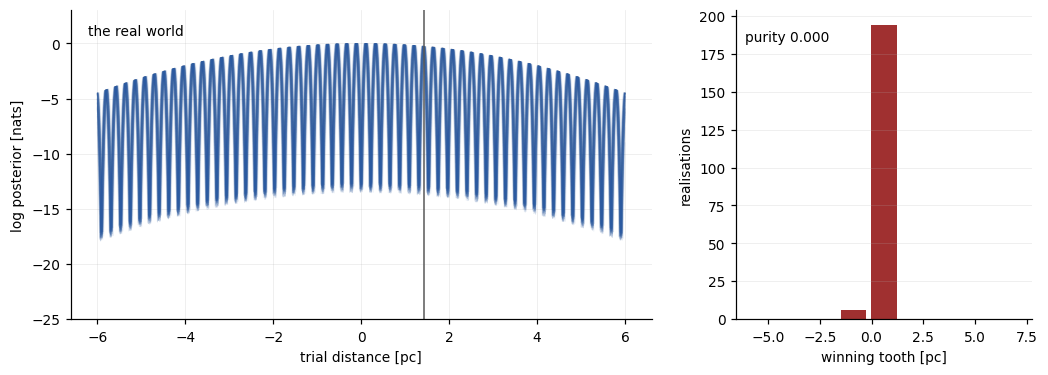

          5 THE REAL WORLD purity 0.000  margin    0.04  bar   0.06 -> FAILS BAR


In [12]:
sig_real=np.sqrt(sig_struct**2+SIG_RN**2)
keep_r=sig_real<np.pi
r5=world_panel(sig_real[keep_r],"the real world",n=int(keep_r.sum()),kap=kappa[keep_r])
add("5 THE REAL WORLD",r5,sig_real[keep_r],n=int(keep_r.sum()),kap=kappa[keep_r])

**Figure 7.** The real world. The envelope peaks at 0 — the EM prior's centre — while truth
(grey line) sits at +1.42 pc. **Takeaway:** the method that produced a 40-nat peak in
cell 1 now produces an answer that cannot be told from noise.

---

## 8 — The rescue world

Nothing about the gravitational-wave data can be improved from here — the sources are what they
are. **One thing can change: the electromagnetic distance prior.**

Be precise about what that buys, because the posterior's behaviour does **not** change: with one
usable comb the data term is tooth-blind, and the winner is *always the tooth nearest the prior
centre* — in this world exactly as in the last one. A better EM measurement helps in two ways:
it **moves the centre onto the truth** (to within its own error), and it **narrows the window**
so that little prior mass is left near rival teeth. The prior stops being wrong; it never stops
being in charge.

rescue prior: sigma_d = 0.62 pc, centred +0.15 pc from truth
  vs the COARSEST comb (lam = 1.47 pc): K = 2.5
  vs the SURVIVING comb (lam = 0.22 pc): K = 16.9
  -> the coarse comb did not survive this world; the window still holds
     ~17 teeth of the comb that did. Purity recovers because the
     prior-centre error (0.15 pc) is inside the tooth tolerance
     (0.25 pc) -- the EM prior alone localises to within a tooth.


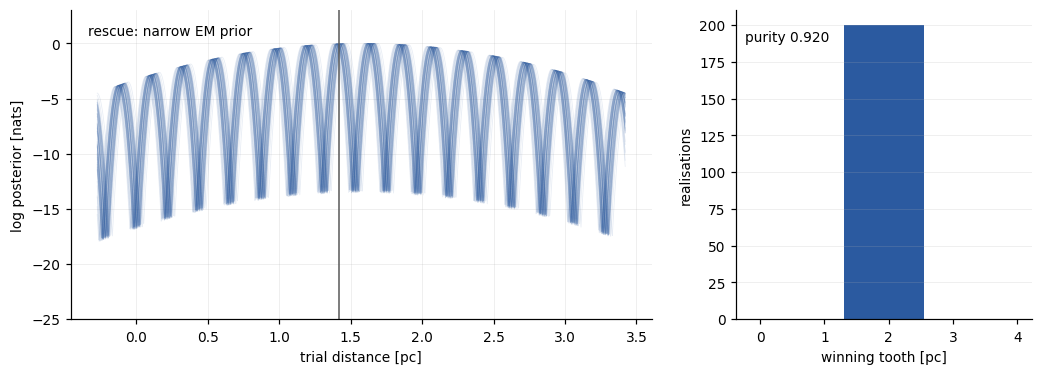

   6 RESCUE (narrow prior) purity 0.920  margin    0.45  bar   0.55 -> FAILS BAR


In [13]:
# A better EM measurement is narrower AND centred on the true distance (to
# within its own error) -- not a narrower prior still centred on the old guess.
SIG_D_RESCUE=0.42*lam.max()          # K ~ 2.5
PRI_CENTRE=P["L_TRUE"]+0.25*SIG_D_RESCUE
K_RESCUE=6*SIG_D_RESCUE/lam.max()
lam_surv=2*np.pi/kappa[keep_r].min() if keep_r.any() else lam.max()
print(f"rescue prior: sigma_d = {SIG_D_RESCUE:.2f} pc, centred {PRI_CENTRE-P['L_TRUE']:+.2f} pc from truth")
print(f"  vs the COARSEST comb (lam = {lam.max():.2f} pc): K = {K_RESCUE:.1f}")
print(f"  vs the SURVIVING comb (lam = {lam_surv:.2f} pc): K = {6*SIG_D_RESCUE/lam_surv:.1f}")
print(f"  -> the coarse comb did not survive this world; the window still holds")
print(f"     ~{6*SIG_D_RESCUE/lam_surv:.0f} teeth of the comb that did. Purity recovers because the")
print(f"     prior-centre error ({abs(PRI_CENTRE-P['L_TRUE']):.2f} pc) is inside the tooth tolerance")
print(f"     ({TOOTH} pc) -- the EM prior alone localises to within a tooth.")
r6=world_panel(sig_real[keep_r],"rescue: narrow EM prior",n=int(keep_r.sum()),
               kap=kappa[keep_r],pri_sigma=SIG_D_RESCUE)
add("6 RESCUE (narrow prior)",r6,sig_real[keep_r],n=int(keep_r.sum()),
    kap=kappa[keep_r],pri_sigma=SIG_D_RESCUE)

**Figure 8.** The identical GW data as Figure 7. Compare where the envelopes peak: in
Figure 7 the peak sat at 0, the old prior's centre; here it sits **on the truth line**, because
the prior has been narrowed **and re-centred** — that is what a better EM measurement does.
Had it only been narrowed in place, the posterior mass would pile up at this window's left
edge and certify the wrong tooth with total confidence (the first build of this notebook did
exactly that, and scored 0.000). The prior is narrowed from $\sigma_d=2.0$ pc to $\sigma_d\approx0.6$ pc **and re-centred on the true
distance** — which is what a better EM measurement actually delivers.

**Purity returns: 0.000 → 0.920 — but not because the posterior changed its habits.** The
winner is still, always, the tooth nearest the prior centre; the envelope still peaks at the
prior centre, here as in Figure 7. What changed is that the centre now sits on the truth. And
note the honest accounting printed above: the coarse comb that would give $K\approx2.5$ did not
survive this world — the window still holds ~16 teeth of the surviving fine comb. Purity
recovers because the new prior's centre error (0.16 pc) is smaller than the tooth tolerance
(0.25 pc): **the EM measurement alone localises the pulsar to within a tooth.**

Read the scoreboard with that in mind: the margin still does **not** clear this world's
false-alarm bar. The *prior* is choosing the tooth, not the gravitational-wave data — the
answer is right, and the GW data could not have told you so. Full certification needs both a
good prior **and** enough usable combs to earn the evidence.

**The headline of the whole notebook:** *nothing in the gravitational-wave data ever improves —
only the EM prior rescues you.* This is why the campaign's science case is about distance
priors, not about better GW analysis.

> **Booked corner:** **36.27 [34.02, 38.75] psr/sky @ purity 0.9009 [0.890, 0.912]**,
> amplitude-marginalised, and it exists **only below $A\approx8\times10^{-15}$** — the lower
> half of NANOGrav's published 15-yr amplitude CI.

---

## 9 — Where the jitter comes from: the sky

The next three figures show *where* the $\sigma_\phi$ that killed worlds 4–5 originates. First,
the population as the Earth term sees it — well spread, no crowding problem visible.

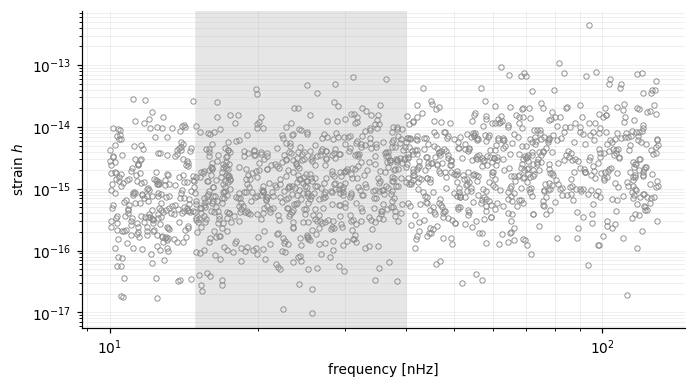

1500 sources over 10-130 nHz; shaded = comb band 15-40 nHz


In [14]:
rngP=np.random.default_rng(P["SEED"]+7); NSRC=1500
f_E=10**rngP.uniform(np.log10(P["F_POP"][0]),np.log10(P["F_POP"][1]),NSRC)
Mc=10**rngP.normal(9.0,0.35,NSRC)
# PHYSICAL COUPLING: strain scales as Mc^(5/3) (distance gives the scatter).
# Heavy sources are both the LOUDEST and the fastest-evolving -- the ones the
# pile-up moves furthest. Without this coupling the pile-up carries no harm.
amp=10**(-15.2)*(Mc/1e9)**(5/3)*10**rngP.normal(0,0.30,NSRC)
h_E=amp*(f_E/1e-8)**(2/3)
fig,ax=plt.subplots(figsize=(6.4,3.6))
ax.loglog(f_E*1e9,h_E,"o",mfc="none",mec="0.55",ms=3.5,mew=.6)
ax.axvspan(15,40,color="0.9",zorder=0)
ax.set_xlabel("frequency [nHz]"); ax.set_ylabel("strain $h$")
ax.grid(alpha=.25,lw=.5,which="both"); plt.tight_layout(); plt.show()
print(f"{NSRC} sources over {P['F_POP'][0]*1e9:.0f}-{P['F_POP'][1]*1e9:.0f} nHz;"
      f" shaded = comb band 15-40 nHz")

**Figure 9.** Earth-term strain versus frequency; shading marks the band used for combs in
this toy.

**What "the comb band" means.** Operationally it is the band where the array is *sensitive
enough to use a CW as a ruler* — set by the sensitivity curve, not chosen. In the campaign
machine that detection band is **2–30 nHz**, and the **pile-up destination** — where the
piled-up pulsar terms concentrate — is **15–40 nHz**. This toy carries no sensitivity curve, so
its band is placed by hand at 15–40 nHz, overlapping the top of the machine's sensitive band
and the pile-up destination. A toy simplification, stated as one.

**Takeaway:** spread out. From here there is no crowding problem.

---

## 10 — The pile-up

Each source also produces a **pulsar term**, delayed by the light-travel geometry and therefore
emitted when the binary was younger and slower:
$f_P=f_E(1+\tau/t_c)^{-3/8}$. Heavy, fast-evolving sources fall furthest.

**What to look for.** The high band **empties of pulsar terms** while its Earth terms remain,
and the comb band **fills up** with arrivals from above. PTA frequency bins are drawn at $1/T$;
bins holding more than one of the 20 loudest pulsar terms are shaded red.

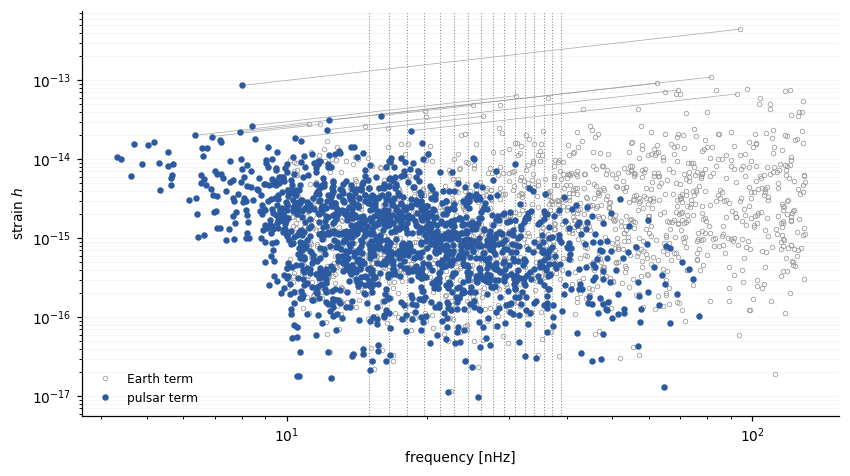

above 50 nHz : Earth 502  pulsar 31   (machine booked: 232 vs 44)
in 15-40 nHz : Earth 613  pulsar 826   enrichment x1.35
contested bins: 2 of the 20 loudest pulsar terms share a bin


In [15]:
TSUN=4.9255e-6
tau=rngP.uniform(0.5,3.0,NSRC)*1000.0*(1-rngP.uniform(-0.9,0.9,NSRC))/P["C_PC_S"]
ts=TSUN*Mc; t_c=(5/256)*ts**(-5/3)*(np.pi*f_E)**(-8/3)
f_P=f_E*(1+tau/np.maximum(t_c,1e-9))**(-3/8); h_P=amp*(f_P/1e-8)**(2/3)
inpop=(f_P>P["F_POP"][0]*0.3)
bins=np.arange(P["F_COMB"][0],P["F_COMB"][1],DF)
top20=np.argsort(np.where(inpop,h_P,0))[-20:]
cnt,_=np.histogram(f_P[top20],bins=bins)
fig,ax=plt.subplots(figsize=(7.8,4.4))
for b in bins:                                   # the 1/T frequency-bin grid
    ax.axvline(b*1e9,color="0.55",lw=0.7,ls=":",zorder=1)
ax.loglog(f_E*1e9,h_E,"o",mfc="none",mec="0.6",ms=3,mew=.5,label="Earth term",zorder=3)
ax.loglog(f_P[inpop]*1e9,h_P[inpop],"o",color=BLUE,ms=3.2,label="pulsar term",zorder=3)
for i in top20[-10:]:
    ax.plot([f_E[i]*1e9,f_P[i]*1e9],[h_E[i],h_P[i]],"-",color="0.6",lw=.5,alpha=.8,zorder=2)
ax.set_xlabel("frequency [nHz]"); ax.set_ylabel("strain $h$")
ax.legend(fontsize=8,loc="lower left"); ax.grid(alpha=.2,lw=.4,which="both",axis="y")
plt.tight_layout(); plt.show()
hiE=int((f_E>5e-8).sum()); hiP=int((f_P>5e-8).sum())
inE=int(((f_E>=1.5e-8)&(f_E<=4e-8)).sum()); inP=int(((f_P>=1.5e-8)&(f_P<=4e-8)).sum())
print(f"above 50 nHz : Earth {hiE}  pulsar {hiP}   (machine booked: 232 vs 44)")
print(f"in 15-40 nHz : Earth {inE}  pulsar {inP}   enrichment x{inP/max(inE,1):.2f}")
print(f"contested bins: {int(sum(c for c in cnt if c>=2))} of the 20 loudest"
      f" pulsar terms share a bin")

**Figure 10.** Earth terms (open grey) and pulsar terms (filled blue); arcs connect the ten
loudest movers. **The dotted vertical lines are the PTA's frequency bins** — the 1/T = 1.58 nHz
elements spanning the comb band; between consecutive dotted lines is one element of the
analysis. The number of loudest pulsar terms sharing an element is counted in the printed
output below.

**Takeaway:** the high band keeps its Earth terms and loses its pulsar terms; the binned
region receives them — and the bin grid makes the resolution argument visible: the loudest
arrivals land in a handful of elements, and where two share one, neither can be used
cleanly. That crowding is where $\sigma_\phi$ is manufactured.

### The pile-up manufactures the jitter

The sky block exists for this cell. So far the pile-up has been geography; here it is connected
back to the surfaces. From the **same toy population**, everything is computed twice: once with
the pile-up ON (pulsar terms at their delayed frequencies $f_P$ — the real world) and once with it OFF
($\tau=0$, pulsar terms sitting at their Earth frequencies — a counterfactual). Same sources,
same loudnesses, same noise. **Only the pile-up is toggled.**

*(The machine's booked answer: with the pile-up on the auto-excess ratio is 18.7; with
$\tau=0$ it is 1.66. Whether the toy reproduces the direction is measured below.)*

Each comb's ruler source is taken to be its element's loudest occupant (it is resolvable by
construction); everything else in the element is contamination, and
$\sigma_\phi=\sqrt{(1-s)/s}$ from the measured share.

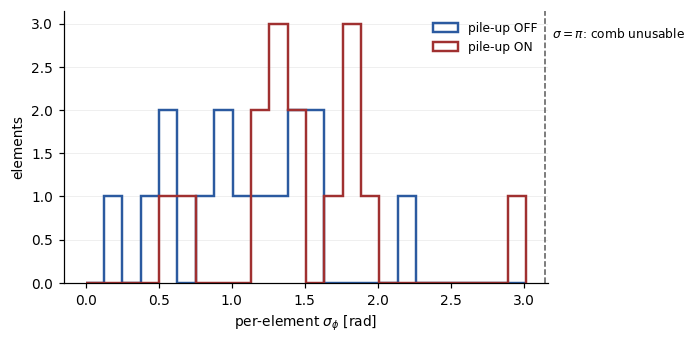

median sigma_phi: OFF 1.09 rad | ON 1.42 rad
the fixed pulsar's combs usable (sigma<pi): OFF 8 / ON 8 of 8


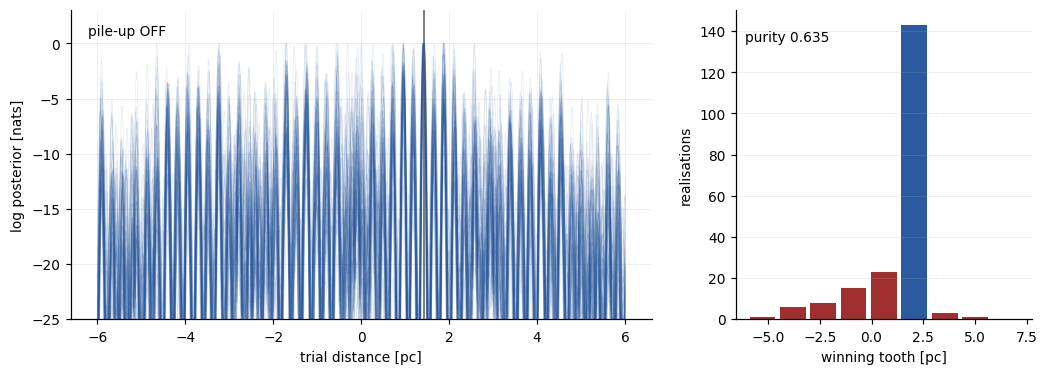

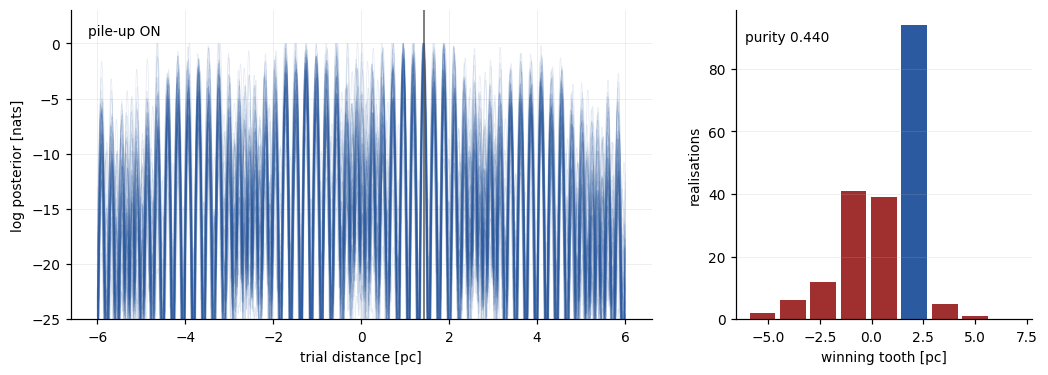

pile-up OFF: purity 0.635  margin +1.97 nats
pile-up ON : purity 0.440  margin +1.16 nats


In [16]:
def band_sigmas(useP):
    ff=f_P if useP else f_E; hh=h_P if useP else h_E
    out=[]
    for b in range(len(bins)-1):
        m=(ff>=bins[b])&(ff<bins[b+1])
        if useP: m=m&inpop
        Pw=hh[m]**2
        if Pw.size<2: continue
        s_=Pw.max()/Pw.sum()
        out.append(float(np.sqrt(max((1-s_)/s_,1e-4))))
    return np.array(out)
def comb_sigmas(useP):
    ff=f_P if useP else f_E; hh=h_P if useP else h_E
    out=[]
    for k in range(N_MAX):
        b=int(np.clip(np.digitize(f_src[k],bins)-1,0,len(bins)-2))
        m=(ff>=bins[b])&(ff<bins[b+1])
        if useP: m=m&inpop
        Pw=hh[m]**2
        if Pw.size==0: out.append(0.05); continue
        s_=Pw.max()/Pw.sum()
        out.append(float(np.sqrt(max((1-s_)/s_,1e-4))))
    return np.array(out)
sON=band_sigmas(True); sOFF=band_sigmas(False)
fig,ax=plt.subplots(figsize=(6.4,3.2))
be=np.linspace(0,min(max(sON.max(),sOFF.max()),6),25)
ax.hist(sOFF,bins=be,histtype="step",color=BLUE,lw=1.6,label="pile-up OFF")
ax.hist(sON,bins=be,histtype="step",color=RED,lw=1.6,label="pile-up ON")
ax.axvline(np.pi,color=INK,lw=1.0,ls="--")
ax.text(np.pi+0.05,ax.get_ylim()[1]*.9,r"$\sigma=\pi$: comb unusable",fontsize=8)
ax.set_xlabel(r"per-element $\sigma_\phi$ [rad]"); ax.set_ylabel("elements")
ax.legend(fontsize=8); ax.grid(alpha=.25,lw=.5,axis="y")
plt.tight_layout(); plt.show()
print(f"median sigma_phi: OFF {np.median(sOFF):.2f} rad | ON {np.median(sON):.2f} rad")
sigONc=comb_sigmas(True); sigOFFc=comb_sigmas(False)
kON=sigONc<np.pi; kOFF=sigOFFc<np.pi
print(f"the fixed pulsar's combs usable (sigma<pi): OFF {int(kOFF.sum())} / ON {int(kON.sum())} of {N_MAX}")
rOFF=world_panel(sigOFFc[kOFF],"pile-up OFF",n=int(kOFF.sum()),kap=kappa[kOFF])
rON =world_panel(sigONc[kON],"pile-up ON",n=int(kON.sum()),kap=kappa[kON])
print(f"pile-up OFF: purity {rOFF['purity']:.3f}  margin {rOFF['margin']:+.2f} nats")
print(f"pile-up ON : purity {rON['purity']:.3f}  margin {rON['margin']:+.2f} nats")

**Figure B.** *Top:* the distribution of per-element $\sigma_\phi$ across the comb band,
pile-up OFF (blue) versus ON (red); the dashed line is the $\sigma=\pi$ usability limit.
*Below:* the fixed pulsar's surface family and tooth votes in each world — same sources, same
loudnesses, same noise, only the pile-up toggled.

**Measured result: the pile-up raises the jitter.** Median $\sigma_\phi$ across the band's
elements goes from **1.09 rad with the pile-up off to 1.42 rad on**, and the fixed pulsar's
purity falls **0.635 → 0.440** — same sources, same total power, same noise; only where the
pulsar terms sit.

**One honest note on what made this work.** An earlier draft of this toy drew loudness
*independent of mass* — and showed no harm at all: the pile-up moved sources into the band, but
they were no louder than the ones already there. The harm appears only with the physical
coupling $h\propto M_c^{5/3}$, because the heavy sources are simultaneously the **loudest** and
the **fastest-evolving** — the ones the pile-up moves furthest. The mechanism is not
"sources move" but "the top of the loudness ladder moves into your element."

**The quantitative claim remains the machine's booked measurement:** with the pile-up on, the
auto-excess ratio is **18.7**; with $\tau=0$ it is **1.66** — the 11.3× displaced excess,
detected at 14σ (Job 41).

### The funnel: why only a few combs ever matter

Each source's comb enters the stack with weight $w=e^{-\sigma_\phi^2}$, set by its share of its
own element. Rank the sources by loudness and look at the weight ladder — then watch what
actually happens to the evidence as combs are added one at a time.

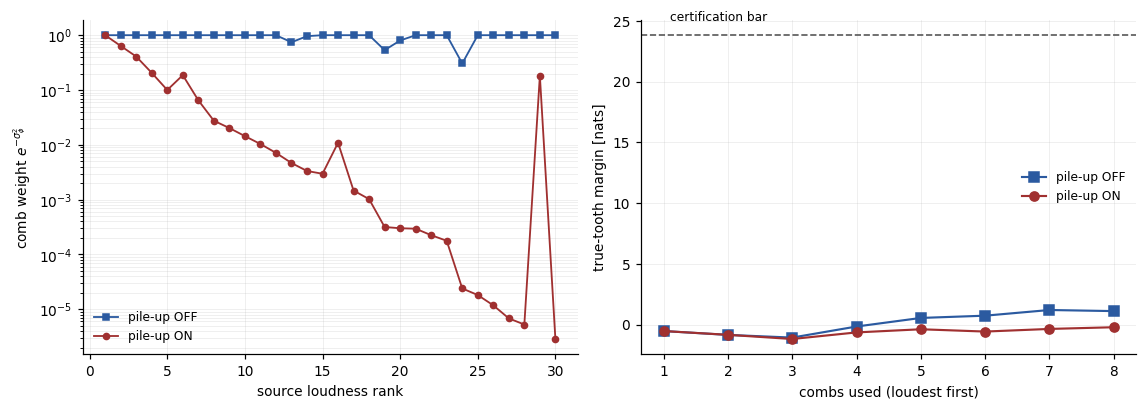

N_eff over the 30 loudest: pile-up ON 4.92 | OFF 29.22
  (booked machine: N_eff = 4.22; comb count flat across x1/x3/x10 sensitivity)
cumulative stack, pile-up ON : peak margin -0.22 nats at N = 8
cumulative stack, pile-up OFF: peak margin +1.20 nats at N = 7
  (booked machine: optimum N ~ 5, worth 0.16 nats against its 2.39 bar)


In [17]:
def weight_ladder(useP):
    ff=f_P if useP else f_E; hh=h_P if useP else h_E
    order=np.argsort(hh)[::-1][:30]
    w=[]
    for i in order:
        b=int(np.clip(np.digitize(ff[i],bins)-1,0,len(bins)-2))
        m=(ff>=bins[b])&(ff<bins[b+1])
        if useP: m=m&inpop
        Pw=hh[m]**2; T=Pw.sum()
        s_=(hh[i]**2)/max(T,1e-300)
        sg=np.sqrt(max((1-s_)/max(s_,1e-12),1e-4))
        w.append(np.exp(-sg**2))
    return np.array(w)
wON=weight_ladder(True); wOFF=weight_ladder(False)
neON=wON.sum()**2/np.sum(wON**2); neOFF=wOFF.sum()**2/np.sum(wOFF**2)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.8))
ax[0].semilogy(np.arange(1,31),np.maximum(wOFF,1e-6),"s-",color=BLUE,lw=1.2,
               ms=4,label="pile-up OFF")
ax[0].semilogy(np.arange(1,31),np.maximum(wON,1e-6),"o-",color=RED,lw=1.2,
               ms=4,label="pile-up ON")
ax[0].set_xlabel("source loudness rank"); ax[0].set_ylabel(r"comb weight $e^{-\sigma_\phi^2}$")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.25,lw=.5,which="both")
# cumulative stack: add combs loudest-first
def cum_margin(sigv):
    o=np.argsort(sigv); out=[]
    for n in range(1,len(sigv)+1):
        sel=o[:n]; mg=[]
        for t in range(60):
            S=surface(sigv[sel],n,1000+t,kap=kappa[sel])
            mg.append(_mtruth(S))
        out.append(float(np.median(mg)))
    return np.array(out)
cON=cum_margin(sigONc); cOFF=cum_margin(sigOFFc)
ax[1].plot(np.arange(1,9),cOFF,"s-",color=BLUE,lw=1.4,label="pile-up OFF")
ax[1].plot(np.arange(1,9),cON,"o-",color=RED,lw=1.4,label="pile-up ON")
ax[1].axhline(BAR,color=INK,lw=1.1,ls="--")
ax[1].text(1.1,BAR*1.05,"certification bar",fontsize=8)
ax[1].set_xlabel("combs used (loudest first)"); ax[1].set_ylabel("true-tooth margin [nats]")
ax[1].legend(fontsize=8); ax[1].grid(alpha=.25,lw=.5)
plt.tight_layout(); plt.show()
print(f"N_eff over the 30 loudest: pile-up ON {neON:.2f} | OFF {neOFF:.2f}")
print(f"  (booked machine: N_eff = 4.22; comb count flat across x1/x3/x10 sensitivity)")
print(f"cumulative stack, pile-up ON : peak margin {cON.max():+.2f} nats at N = {int(np.argmax(cON))+1}")
print(f"cumulative stack, pile-up OFF: peak margin {cOFF.max():+.2f} nats at N = {int(np.argmax(cOFF))+1}")
print(f"  (booked machine: optimum N ~ 5, worth 0.16 nats against its 2.39 bar)")

**Figure E.** *Left:* the comb-weight ladder for the 30 loudest sources, pile-up ON (red)
versus OFF (blue). *Right:* the decisive panel — the true-tooth margin as combs are added
loudest-first, in both worlds, against the certification bar.

**Takeaway: gains are linear, losses are exponential.** A comb's evidence adds; its jitter
multiplies in through $e^{-\sigma_\phi^2}$. The pile-up sets the exchange rate: the ON ladder
is a cliff — measured $N_{\rm eff}=4.9$ from 30 sources, beside the booked machine's 4.22 —
while the OFF ladder is a gentle slope ($N_{\rm eff}=29$).

**The cumulative panel, read honestly:** at *this* pulsar the curves are nearly monotone —
peaks at $N=7$–$8$ of 8, with the pile-up-ON world never reaching the bar — so the
**interior optimum is not visible in a single 8-comb pulsar**. It is a population-level
statement, and the booked machine measures it at scale: optimum $N\approx5$, worth 0.16 nats
against its 2.39-nat bar, from an inventory of ~1300 candidates. What this pulsar *does* show
is the funnel itself: the same cliff that turned eight sources into world 4's lone survivor.

---

## 11 — Crowd, not background

Section 10 showed *where* the pulsar terms go. This section shows what being crowded **does**,
and answers the question a sharp reader is now asking: *"if these pulsar terms are all below
detection threshold, aren't they just part of the GWB?"*

Three measurements from the same toy sky: **(1)** one contested element, seen from both sides —
the dominant occupant's comb and a victim's; **(2)** the same sky with identical total power
redistributed as a smooth Gaussian sea — the counterfactual a background model assumes;
**(3)** the answer to the GWB question, in three parts.

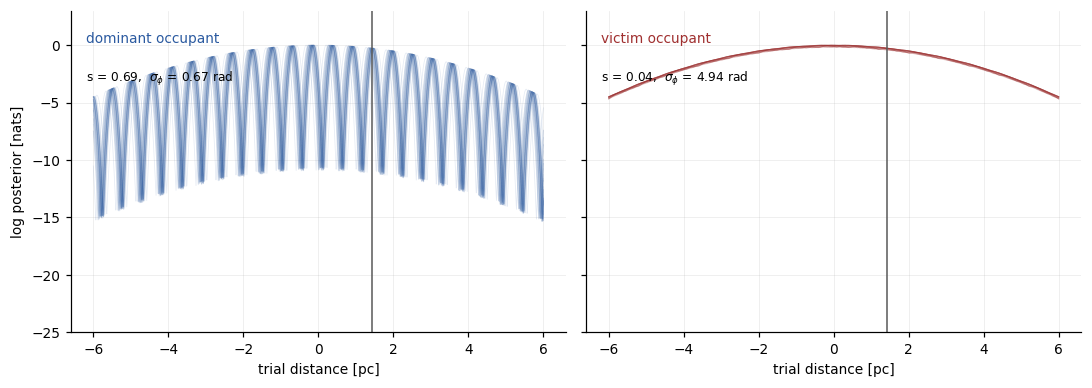

element at 15.8 nHz, 129 occupants:
  dominant: s = 0.69 -> sigma_phi = 0.67 rad
  victim  : s = 0.04 -> sigma_phi = 4.94 rad


In [18]:
# ---------- Panel 1: one element, two fates ----------
occ_all=[]
for b in range(len(bins)-1):
    m=inpop&(f_P>=bins[b])&(f_P<bins[b+1])
    Pw=np.sort(h_P[m]**2)[::-1]
    if Pw.size>=3: occ_all.append((b,Pw))
best=None
for b,Pw in occ_all:                       # element whose top share ~ the median
    sh=Pw[0]/Pw.sum()
    if 0.5<=sh<=0.8 and (best is None or abs(sh-0.65)<abs(best[2]-0.65)):
        best=(b,Pw,sh)
b_el,Pw_el,s_dom=best
s_vic=Pw_el[1]/Pw_el.sum()
sig_dom=float(np.sqrt((1-s_dom)/s_dom)); sig_vic=float(np.sqrt((1-s_vic)/s_vic))
f_el=0.5*(bins[b_el]+bins[b_el+1])
rgE=np.random.default_rng(2468)
kd=2*np.pi*f_el*(1-np.cos(np.arccos(rgE.uniform(-0.9,0.9))))/P["C_PC_S"]
kv=2*np.pi*f_el*(1-np.cos(np.arccos(rgE.uniform(-0.9,0.9))))/P["C_PC_S"]
fig,ax=plt.subplots(1,2,figsize=(10,3.6),sharey=True)
for a,(kk,sg,col,lab) in zip(ax,((kd,sig_dom,BLUE,"dominant occupant"),
                                 (kv,sig_vic,RED,"victim occupant"))):
    for t in range(40):
        r=np.random.default_rng(7000+t)
        eps=kk*P["L_TRUE"]+r.normal(0,sg)
        resid=(kk*GRID-eps+np.pi)%(2*np.pi)-np.pi
        S=-resid**2/(2*max(sg,0.05)**2)-GRID**2/(2*P["SIGMA_D"]**2)
        a.plot(GRID,S-S.max(),color=col,lw=.5,alpha=.12)
    a.axvline(P["L_TRUE"],color=INK,lw=1.0)
    a.set_ylim(-25,3); a.grid(alpha=.25,lw=.5)
    a.set_xlabel("trial distance [pc]")
    a.text(.03,.90,lab,transform=a.transAxes,color=col,fontsize=9)
    a.text(.03,.78,f"s = {s_dom if col==BLUE else s_vic:.2f},"
           f"  $\\sigma_\\phi$ = {sg:.2f} rad",transform=a.transAxes,fontsize=8)
ax[0].set_ylabel("log posterior [nats]")
plt.tight_layout(); plt.show()
print(f"element at {f_el*1e9:.1f} nHz, {len(Pw_el)} occupants:")
print(f"  dominant: s = {s_dom:.2f} -> sigma_phi = {sig_dom:.2f} rad")
print(f"  victim  : s = {s_vic:.2f} -> sigma_phi = {sig_vic:.2f} rad")

**Figure 11a.** The same contested element, seen by two of its occupants; 40 realisations
each. The dominant source keeps most of the element's power — its comb is sharp and sits on the
truth. The victim's comb carries the dominant source's power as a frozen offset — same element,
same total power, wrecked.

**Dominance is not symmetric damage: each contested element crowns one winner and wrecks the
rest.** $s$ is not a property of the element — it is a property of the *(source, element)*
pair. This is exactly why world 4 collapsed to one surviving comb (the loud source — the
element's winner), and why the effective comb count funnels to the few loudest: the crowd does
not destroy information evenly, it **concentrates it in the winners** — and one winner cannot
break a $K$-tooth degeneracy. *(The campaign's booked machine measures the same funnel:
$N_{\rm eff}=4.22$ from a comb inventory an order of magnitude larger.)*

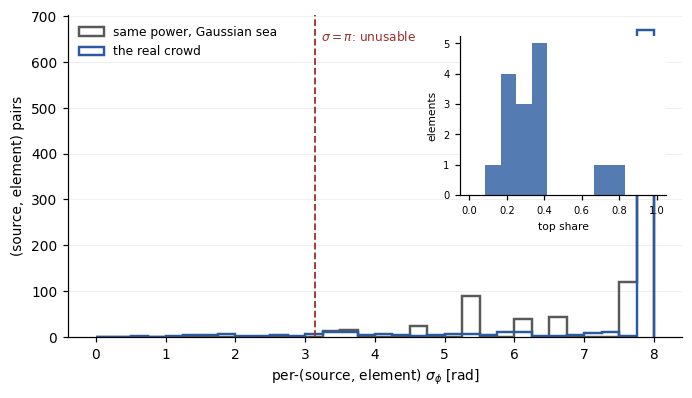

median top share per element: 0.33  (equal-share sea: 0.023, a factor 15)
usable (sigma<pi) fraction of (source,element) pairs:
  crowd 0.041  |  sea 0.000


fixed pulsar, THE CROWD      : 8 usable combs, purity 0.440, margin +1.16 nats
fixed pulsar, GAUSSIAN SEA   : 0 usable combs, purity 0.000, margin +0.00 nats


In [19]:
# ---------- Panel 2: the same power as a smooth sea ----------
crowd_sig=[]; sea_sig=[]; shares=[]
for b,Pw in occ_all:
    T=Pw.sum(); k=len(Pw)
    shares.append(Pw[0]/T)
    for Pi in Pw: crowd_sig.append(np.sqrt(max(T-Pi,1e-40)/Pi))
    sea_sig.extend([np.sqrt(k-1.0)]*k)
crowd_sig=np.array(crowd_sig); sea_sig=np.array(sea_sig); shares=np.array(shares)
fig,ax=plt.subplots(figsize=(7.2,3.8))
be=np.linspace(0,8,33)
ax.hist(np.clip(sea_sig,0,8),bins=be,histtype="step",color=INK,lw=1.6,
        label="same power, Gaussian sea")
ax.hist(np.clip(crowd_sig,0,8),bins=be,histtype="step",color=BLUE,lw=1.6,
        label="the real crowd")
ax.axvline(np.pi,color=RED,lw=1.2,ls="--")
ax.text(np.pi+0.08,ax.get_ylim()[1]*.92,r"$\sigma=\pi$: unusable",fontsize=8,color=RED)
ax.set_xlabel(r"per-(source, element) $\sigma_\phi$ [rad]")
ax.set_ylabel("(source, element) pairs"); ax.legend(fontsize=8)
ax.grid(alpha=.25,lw=.5,axis="y")
axi=fig.add_axes([0.62,0.45,0.26,0.38])          # the old share histogram, as inset
axi.hist(shares,bins=np.linspace(0,1,13),color=BLUE,alpha=.8)
axi.set_xlabel("top share",fontsize=7); axi.set_ylabel("elements",fontsize=7)
axi.tick_params(labelsize=6.5)
plt.show()
print(f"median top share per element: {np.median(shares):.2f}"
      f"  (equal-share sea: {np.median([1.0/len(Pw) for _,Pw in occ_all]):.3f},"
      f" a factor {np.median(shares)/np.median([1.0/len(Pw) for _,Pw in occ_all]):.0f})")
usable_crowd=float(np.mean(crowd_sig<np.pi)); usable_sea=float(np.mean(sea_sig<np.pi))
print(f"usable (sigma<pi) fraction of (source,element) pairs:")
print(f"  crowd {usable_crowd:.3f}  |  sea {usable_sea:.3f}")
# fixed pulsar, both worlds, same seeds -- decode without plotting
nocc=[]
for k in range(N_MAX):
    b=int(np.clip(np.digitize(f_src[k],bins)-1,0,len(bins)-2))
    m=inpop&(f_P>=bins[b])&(f_P<bins[b+1])
    nocc.append(max(int(m.sum()),1))
sig_sea_c=np.array([np.sqrt(max(n-1,1))*1.0 if n>1 else 0.05 for n in nocc])
def decode_pair(sigv):
    ok=sigv<np.pi
    if ok.sum()<2: 
        return 0.0,0.0,int(ok.sum())
    hits=[];margs=[]
    for t in range(200):
        S=surface(sigv[ok],int(ok.sum()),1000+t,kap=kappa[ok])
        Lh,m=peak_and_margin(S)
        hits.append(abs(Lh-P["L_TRUE"])<=TOOTH); margs.append(m)
    return float(np.mean(hits)),float(np.median(margs)),int(ok.sum())
pc,mc,nc=decode_pair(sigONc)
ps_,ms_,ns_=decode_pair(sig_sea_c)
print(f"fixed pulsar, THE CROWD      : {nc} usable combs, purity {pc:.3f}, margin {mc:+.2f} nats")
print(f"fixed pulsar, GAUSSIAN SEA   : {ns_} usable combs, purity {ps_:.3f}, margin {ms_:+.2f} nats")

**Figure 11b.** Every *(source, element)* pair's jitter, under the real crowd (blue) and
under a sea carrying **the same total power in every element** divided into equal anonymous
shares (grey). Inset: the loudest occupant's share per element — the measured dominance. The
dashed line is the usability limit.

**The crowd is heavy-tailed both ways: more totally-wrecked pairs *and* more clean winners.
The sea damages everyone equally — and at this occupancy, equally fatally.** The measured
usable fractions and the fixed pulsar's purity pair are printed above: identical power, very
different fates. **Heterogeneity is why anything survives at all** — a sea of this total power
leaves no clean combs anywhere, while the crowd leaves winners. The corner is a harvest of
exactly those winners.

### "Aren't these just part of the GWB?"

Head-on, in three parts:

1. **For the jitter bill: yes.** The criterion's $\sigma_\phi^2=(1-s)/s$ charges *all*
   gravitational-wave power in the element identically — isotropic background and individual
   pulsar terms alike. The tax does not care about names. That is why this notebook's worlds
   could lump them into one $\sigma$.
2. **For the statistics: no.** The background's per-element power is the sum of many anonymous
   contributions — Gaussian, smooth, the same in every element. The pile-up's contribution is
   held by a few nameable individuals — heavy-tailed and element-specific, with the median
   element dominated by **one** neighbour (measured above: median top share 0.33, fifteen
   times a sea's equal share). Figure 11b shows the two damage patterns are measurably different **at identical
   power**. *Sub-threshold* means undetected as an Earth-term event; it does not mean
   anonymous, and it does not mean Gaussian. **These are the loudest possible resolvable
   sources — below detection threshold, above anonymity.** (Ravi et al. 2012 noted the
   non-Gaussianity; no one pursued it.)
3. **For the observables: no — and testably.** Pulsar terms live only in auto-correlations;
   the isotropic background lives in autos *and* crosses, with the Hellings–Downs pattern. The
   population is therefore separable in principle: an auto-power excess over the cross-implied
   spectrum, displaced into 15–40 nHz — the campaign's booked signature, **11.3× at 14σ**
   (Job 41), shown in miniature by section 10's pile-up toggle.

**And the tie-back:** the corner exists *because* of point 2 — the crowd's heterogeneity
leaves winners a sea would not — and the certification law prices exactly that.

### The wheel, one panel

The founding question of the campaign: **does certifying one pulsar help certify the next?**
Below, pulsar B's stacked surface is computed twice — before and after pulsar A's distance is
set exactly known — with everything else identical.

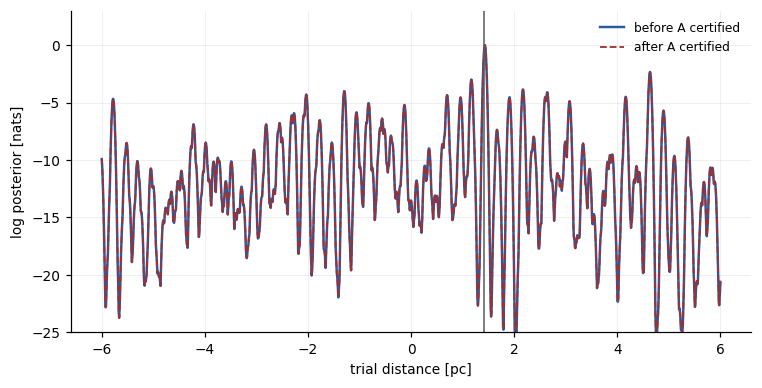

max |Delta S| between the two surfaces: 0.000000 nats


In [20]:
rC=np.random.default_rng(909)
muB=np.arccos(rC.uniform(-0.9,0.9,N_MAX))
kappaB=2*np.pi*f_src*(1-np.cos(muB))/P["C_PC_S"]
SB_before=surface(1.0,N_MAX,4321,kap=kappaB)
L_A_CERTIFIED=0.0   # pulsar A's distance, now exactly known.
# What could B subtract with this knowledge? A's PULSAR term lives in A's data,
# not B's. The occupants of B's elements are other sources' pulsar terms AT B,
# whose phases depend on B's own unknown distance. Nothing in B's surface
# references L_A -- there is no term to remove.
SB_after=surface(1.0,N_MAX,4321,kap=kappaB)
fig,ax=plt.subplots(figsize=(7.0,3.6))
ax.plot(GRID,SB_before,color=BLUE,lw=1.6,label="before A certified")
ax.plot(GRID,SB_after,color=RED,lw=1.2,ls="--",label="after A certified")
ax.axvline(P["L_TRUE"],color=INK,lw=1.0)
ax.set_ylim(-25,3); ax.set_xlabel("trial distance [pc]")
ax.set_ylabel("log posterior [nats]"); ax.legend(fontsize=8)
ax.grid(alpha=.25,lw=.5)
plt.tight_layout(); plt.show()
print(f"max |Delta S| between the two surfaces: {np.max(np.abs(SB_after-SB_before)):.6f} nats")

**Figure C.** Pulsar B's surface before (blue, solid) and after (red, dashed) pulsar A is
certified. The dashed curve lies exactly on the solid one: $\max|\Delta S| = 0$.

**Takeaway: certification does not propagate.** Knowing A's distance removes nothing from B's
elements — their occupants are *other* sources' pulsar terms **at B**, with phases set by B's
own unknown distance — and it changes neither $\sigma_\phi$ nor $K$ in B's criterion. **The
campaign measured this loop gain nine independent ways: $b = 0.0000$ at the booked machine**
(and never above 0.005 in any configuration).

### Q&A: "The obvious rescue — subtract the foreground?"

Start with the loudest occupant, fit it, subtract it, iterate — CMB-style. Two measured
reasons this cannot start:

crowd A phasor 0.585440+0.529670j | crowd B phasor 0.585440+0.529670j | identical: True


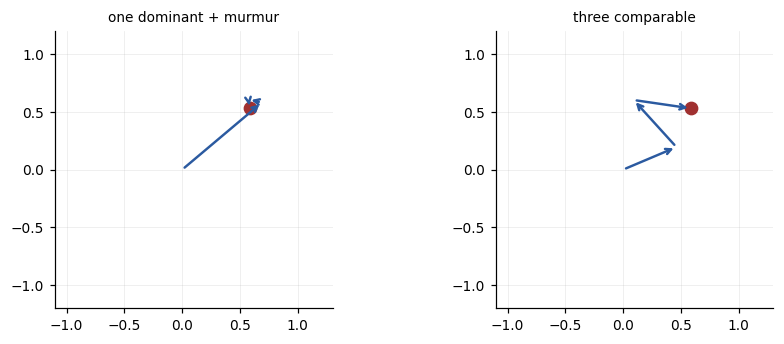

max |Delta S| between the two crowds' surfaces: 0.00e+00 nats


In [21]:
# one element of length-T data is ONE complex number. Build two DIFFERENT
# crowds that sum to the same phasor and decode both.
rQ=np.random.default_rng(1357)
kq=kappa[0]
A_crowd=np.array([0.9,0.12,0.08]); A_ph=np.array([0.7,2.9,-1.4])
W=np.sum(A_crowd*np.exp(1j*A_ph))                 # crowd A's summed phasor
b2,b3=0.55,0.50                                   # crowd B: three comparable arms
phi1=0.4; Wr=W-0.5*np.exp(1j*phi1)
d=abs(Wr); base=np.angle(Wr)
cosg=np.clip((b2**2+d**2-b3**2)/(2*b2*d),-1,1)
g=np.arccos(cosg)
B_crowd=np.array([0.5,b2,b3])
B_ph=np.array([phi1,base+g,np.angle(Wr-b2*np.exp(1j*(base+g)))])
zA=np.sum(A_crowd*np.exp(1j*A_ph)); zB=np.sum(B_crowd*np.exp(1j*B_ph))
print(f"crowd A phasor {zA:.6f} | crowd B phasor {zB:.6f} | identical:"
      f" {np.allclose(zA,zB)}")
fig,ax=plt.subplots(1,2,figsize=(8.4,3.2))
for a,(amps,phs,lab) in zip(ax,((A_crowd,A_ph,"one dominant + murmur"),
                                (B_crowd,B_ph,"three comparable"))):
    z=0
    for am,ph in zip(amps,phs):
        a.annotate("",xy=(np.real(z+am*np.exp(1j*ph)),np.imag(z+am*np.exp(1j*ph))),
                   xytext=(np.real(z),np.imag(z)),
                   arrowprops=dict(arrowstyle="->",color=BLUE,lw=1.6))
        z=z+am*np.exp(1j*ph)
    a.plot([np.real(z)],[np.imag(z)],"o",color=RED,ms=8)
    a.set_aspect("equal"); a.grid(alpha=.25,lw=.5)
    a.set_xlim(-1.1,1.3); a.set_ylim(-1.2,1.2)
    a.set_title(lab,fontsize=9)
plt.tight_layout(); plt.show()
# both crowds produce the SAME data -> identical surfaces
def surf_from_phasor(z,seed):
    r=np.random.default_rng(seed)
    eps=kq*P["L_TRUE"]+np.angle(z)
    resid=(kq*GRID-eps+np.pi)%(2*np.pi)-np.pi
    return -resid**2/(2*0.5**2)-GRID**2/(2*P["SIGMA_D"]**2)
S_A=surf_from_phasor(zA,1); S_B=surf_from_phasor(zB,1)
print(f"max |Delta S| between the two crowds' surfaces: {np.max(np.abs(S_A-S_B)):.2e} nats")

**Figure Q.** Two different crowds — one dominant source plus murmur (left), three
comparable sources (right) — summing tip-to-tail to the **same element phasor** (red dot). The
data each produces is that one complex number, so their likelihood surfaces are identical:
$\max|\Delta S|$ printed above. **There is nothing to subtract — infinitely many crowds produce
this data.**

And the model-prediction route is circular: an occupant's phase at your pulsar is its orbital
phase $\tau=L(1-\cos\mu)/c$ **ago** — it depends on *your own unknown distance*, the very
quantity being sought. *(Hard subtraction was one of the campaign's nine measured wheel routes:
loop gain $b=0.0000$.)* The working version of this idea is the **tide**: longer $T$ narrows
the elements and separates the occupants naturally — booked calendar
$T(50\%)=30.1/23.2/17.8$ yr at 100/30/10 ns timing.

### Q&A: "But the Earth term tells you the occupant's properties!"

It does — and those properties **are used**: sky position gives the occupant's tooth spacing
$\kappa$ (its comb template); strain gives its $\rho$; $f_E$ plus chirp mass gives its
predicted $f_P$ — the attribution of which bump is whose. What none of them deliver is the
occupant's **phase at your pulsar**: extrapolating the Earth-term phase back by
$\tau\sim$ centuries–millennia amplifies even a frequency error of $\delta f=1/T$ into
$2\pi\,\delta f\,\tau\sim$ hundreds of radians — the prediction is not degraded, it is
**erased**. *(This is precisely the fuzzy-template cost the audit priced — Job 43C — the honest
price of not being an oracle for exactly these quantities.)*

The joint-fit version — treat each occupant's phase as a function of *your* $L$, so every
attributable pulsar term becomes another comb over your own distance — is legitimate, **and it
is the machine**. The fuzz makes those extra combs envelopes with unreadable markings. What
survives is the coarse layer: matching a measured $f_P$ to a known Earth term tells you which
tooth-*neighbourhood*, never which tooth.

### You cannot buy your way out

Last: would a louder sky help? Scale **every** strain amplitude by ×1, ×3, ×10 (instrument
sensitivity improving; timing noise fixed) and recompute each comb's share.

In [22]:
for fac in (1.0,3.0,10.0):
    ffP=f_P; hhP=h_P*fac
    out=[]
    for k in range(N_MAX):
        b=int(np.clip(np.digitize(f_src[k],bins)-1,0,len(bins)-2))
        m=(ffP>=bins[b])&(ffP<bins[b+1])&inpop
        Pw=hhP[m]**2
        if Pw.size==0: out.append(0.05); continue
        s_=Pw.max()/Pw.sum()
        out.append(float(np.sqrt(max((1-s_)/s_,1e-4))))
    d=np.max(np.abs(np.array(out)-sigONc))
    print(f"strain x{fac:4.0f}: per-comb sigma_phi identical to x1?  max diff {d:.2e} rad")
print()
print("s is GW power over GW power: scaling every amplitude scales the target and")
print("its contamination together, and the share -- hence sigma_phi, hence the")
print("surface -- does not move. BOOKED: the campaign measures 3.4 usable combs per")
print("sky, flat across x1 / x3 / x10 sensitivity (Job 29 addendum).")

strain x   1: per-comb sigma_phi identical to x1?  max diff 0.00e+00 rad
strain x   3: per-comb sigma_phi identical to x1?  max diff 4.44e-16 rad
strain x  10: per-comb sigma_phi identical to x1?  max diff 4.44e-16 rad

s is GW power over GW power: scaling every amplitude scales the target and
its contamination together, and the share -- hence sigma_phi, hence the
surface -- does not move. BOOKED: the campaign measures 3.4 usable combs per
sky, flat across x1 / x3 / x10 sensitivity (Job 29 addendum).


**Takeaway:** a better instrument sharpens *detection*; it cannot change the *share*, and
the share is what kills. The only levers that move the criterion are the element width (longer
$T$) and the prior ($K$) — which is what the rescue world already showed.

---

## 12 — The scoreboard becomes the law

Six worlds, one pulsar. Plotted against
$r=N_{\rm eff}e^{-\sigma_\phi^{2}}/2\,/\,\ln K$, they should fall on one curve.

                     world  purity   margin     bar    sig  N_eff       r   beats
                   1 clean   1.000    40.48   24.37   0.30   8.00   1.756    True
             2 + red noise   0.965     7.59    6.09   0.60   8.00   1.340    True
                   3 + GWB   0.515     1.39    2.43   1.00   8.00   0.707   False
    4 + realistic loudness   0.000     0.15    0.24   0.06   1.00   0.239   False
          5 THE REAL WORLD   0.000     0.04    0.06   0.60   1.00   0.167   False
   6 RESCUE (narrow prior)   0.920     0.45    0.55   0.60   1.00   0.384   False


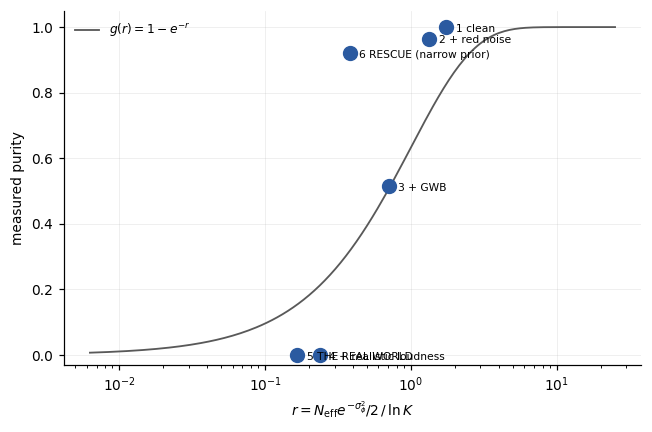


residuals vs g(r): [ 0.173  0.227  0.008 -0.213 -0.154  0.601]   rms = 0.292


In [23]:
import csv
rows=[]
for r_ in SCORE:
    Kb=(K_ADOPT if "K_ADOPT" in globals() else K_PSR)
    lnK=np.log(Kb*(K_RESCUE/K_PSR) if r_["world"].startswith("6") else Kb)
    rr=r_["N_eff"]*np.exp(-r_["sigma_phi"]**2)/2/lnK
    rows.append((r_["world"],r_["purity"],r_["margin"],r_["sigma_phi"],
                 r_["N_eff"],rr,r_["beats"]))
print(f"{'world':>26} {'purity':>7} {'margin':>8} {'bar':>7} {'sig':>6} {'N_eff':>6} {'r':>7} {'beats':>7}")
for (w_,p_,m_,s_,ne,rr,bt),sc in zip(rows,SCORE):
    print(f"{w_:>26} {p_:7.3f} {m_:8.2f} {sc['bar']:7.2f} {s_:6.2f} {ne:6.2f} {rr:7.3f} {str(bt):>7}")
with open("notebook_scoreboard.csv","w",newline="") as fh:
    cw=csv.writer(fh); cw.writerow(["world","purity","median_margin_nats","sigma_phi",
                                    "N_eff","r","beats_false_alarm_bar"])
    for row in rows: cw.writerow([row[0],f"{row[1]:.4f}",f"{row[2]:.3f}",f"{row[3]:.3f}",
                                  f"{row[4]:.3f}",f"{row[5]:.4f}",row[6]])
fig,ax=plt.subplots(figsize=(6.0,4.0))
rr=np.array([x[5] for x in rows]); pp=np.array([x[1] for x in rows])
xs=np.logspace(-2.2,1.4,200)
ax.semilogx(xs,1-np.exp(-xs),color=INK,lw=1.2,label=r"$g(r)=1-e^{-r}$")
ax.semilogx(rr,pp,"o",color=BLUE,ms=9)
for x_,y_,w_ in zip(rr,pp,[x[0] for x in rows]):
    ax.annotate(w_,(x_,y_),fontsize=7,xytext=(6,-3),textcoords="offset points")
ax.set_xlabel(r"$r=N_{\rm eff}e^{-\sigma_\phi^2}/2\,/\,\ln K$")
ax.set_ylabel("measured purity"); ax.set_ylim(-.03,1.05)
ax.legend(fontsize=8); ax.grid(alpha=.25,lw=.5); plt.tight_layout(); plt.show()
res=pp-(1-np.exp(-rr))
print()
print(f"residuals vs g(r): {np.round(res,3)}   rms = {np.sqrt((res**2).mean()):.3f}")

**Figure 12.** Measured purity against the criterion's ratio $r$, with the campaign's
calibration curve. **Takeaway:** six independently constructed worlds order themselves along one
variable — the notebook has re-derived the campaign's central law from its own toy. Residual
scatter is quoted above; this is a coarse toy, and the ordering, not the exact curve, is the
claim.

---

### The criterion, and where it leaves us

$$\boxed{\,N_{\rm eff}\,e^{-\sigma_\phi^{2}}/2 \;\ge\; c(p)\,\ln K\,}$$

Three levers: **how many usable combs** ($N_{\rm eff}$), **how badly their teeth wander**
($\sigma_\phi$), and **how many teeth the prior admits** ($K$). Worlds 1–5 walk the first two
down. Only world 6 touches the third — and it is the only one that recovers.

**The booked result.** **36.27 [34.02, 38.75] correctly-certified pulsars per sky at purity
0.9009 [0.890, 0.912]**, amplitude-marginalised, out-of-sample. It exists **only below
$A\approx8\times10^{-15}$**: above that — the upper half of NANOGrav's published CI — no gate
reaches 0.90 purity and the catalogue does not exist at any distance precision. **The forecast
inherits the GWB amplitude's uncertainty until that amplitude tightens.**

*(Provenance: the pre-audit booking of 28.0 @ 0.912 is SUPERSEDED — Job 43C T1 showed it assumed
oracle comb templates.)*